# Rice-Field Weed Classification with a Compact CNN — **Final Notebook**

This notebook reproduces the final study of the thesis in one place: data pipeline, the proposed model, all
comparison models, robustness checks, explanation maps and the advisory layer.

**Task.** 26 weed species from two merged datasets (Rice Field Weed BD V4, 11 classes; Individual Weed Species,
16 classes; *Commelina benghalensis* occurs in both and is merged): 21,464 images after removing white-background
images, split 70/15/15 (15,024 / 3,219 / 3,221) with seed 42. Primary metric: **test macro-F1**.

**Proposed model — WeedNet-v4 with a QKV attention head (W2), 0.54 M parameters.**
ImageNet-pretrained MobileNetV3-Small stem (first 9 layers) → 3 new MobileNetV3-style blocks → multi-head
self-attention head with a [CLS] token. All layers trained from the start with one learning rate (3e-4), weighted
random sampler, ≤ 50 epochs with early stopping.

| Part | What | Sections |
|---|---|---|
| 0 | Data: download, merge, white-background filter, split, Reinhard harmonization, duplicate check, weighted sampler | 0–10 |
| 1 | Models and training (resumable; finished models are loaded instead of retrained) | 11–15 |
| 2 | Results: repeatability over 3 seeds, comparison with same-size models, overfitting, per-class results, source test | 16–20 |
| 3 | Attention maps and their faithfulness | 21–22 |
| 4 | Calibration and the advisory layer (species / weed group / "not sure" + management advice) | 23–25 |
| 5 | CPU latency and final summary | 26–27 |

**Models**

| ID | Model | Params | Seeds |
|---|---|---|---|
| **W2** | **WeedNet-v4 + QKV attention head (proposed)** | 0.542 M | 42, 43, 44 |
| W1 | WeedNet-v4, plain pooled head (ablation: no attention) | 0.513 M | 42, 43, 44 |
| B1 | MobileNetV3-Small 0.5× | 0.595 M | 42, 43, 44 |
| M1 | MobileNetV3-Small 1.0× (3× larger reference) | 1.545 M | 42, 43, 44 |
| S1 | ShuffleNetV2 0.5× | 0.368 M | 42 |
| L1 | PP-LCNet 0.5× | 0.633 M | 42 |
| Q1 | SqueezeNet 1.1 | 0.736 M | 42 |
| SRC_d1, SRC_d2 | W1 trained on one source dataset only (source test) | 0.51 M | 42 |

### How to run on Kaggle (GPU T4, Internet ON, always **Save Version → Save & Run All**)

**A. Re-use the trained models (recommended): ~45 min – 1 h, one session.**
Attach (Add Input → Your Work → Notebooks) **weednet-v7** (holds W1/W2/B1/M1 × 3 seeds and S1/L1/Q1) and
**weednet-v5 (Version 2)** (holds the source-test models). Nothing is trained; every result is recomputed.

**B. Train everything from scratch: ~38 GPU-hours, 4 sessions** (Kaggle allows ~30 GPU-h per week, so about
two weeks). Attach nothing. Each session stops cleanly at 11 h and ends with `INCOMPLETE`; attach **this
notebook's previous version** and run again. Training continues exactly where it stopped. Order: all seed-42 models
first (~17 h), then the source test (~2.5 h), then seeds 43 and 44 (~19 h). The last cell says what to do next.

Mixed use also works: anything attached is loaded, anything missing is trained.

---
# Part 0 — Data Pipeline

## 0. Install Dependencies

`gdown` (downloads the two dataset zips from Google Drive) and `timm` (PP-LCNet and MobileNetV3-Small 0.5×).

In [1]:
!pip install -q gdown timm

## 1. Imports & Global Config

Device selection prefers CUDA (Kaggle GPU), then Apple Silicon MPS, then CPU.

In [2]:
import os
import re
import time
import copy
import json
import shutil
import zipfile
import random as pyrandom

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset, WeightedRandomSampler
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report
)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
pyrandom.seed(SEED)

# Device selection: CUDA (Kaggle GPU) > Apple Silicon (MPS, if run elsewhere) > CPU
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f"Device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
elif device.type == 'mps':
    print("Using Apple Silicon GPU via MPS backend")
else:
    print("No GPU detected — check Kaggle's Settings panel and turn the Accelerator to GPU.")

Device: cuda
GPU: Tesla T4


## 1b. Configuration

- **Protocol** (`LR`, `MAX_EPOCHS`, `EARLY_STOP_PATIENCE`, `FREEZE_UPTO`, `ATTN_*`): identical for every model.
  Changing it makes re-used models from earlier runs incomparable with new ones.
- **`SEEDS`, `SEED_REFS`, `SAME_SIZE`, `RUN_SOURCE_TEST`**: which models are trained/loaded (see the table above).
- **`N_FAITH`, `N_SANITY`, `TARGET_ACC`**: faithfulness test size and the required accuracy of the advisory
  layer's answers.
- **`OUT_DIR`, `RESTORE_FOLDERS`**: results go to `weednet_final_outputs/`; Section 1c copies in the model files
  it needs from attached earlier outputs (this notebook's own first, then v7, v5, v6, v4).
- **`TIME_BUDGET_HOURS = 11`**: stop cleanly before Kaggle's 12 h limit so the version's output is saved.

In [3]:
import glob
from scipy.stats import binomtest, spearmanr
from sklearn.metrics import (top_k_accuracy_score, roc_auc_score, cohen_kappa_score,
                             matthews_corrcoef, precision_recall_fscore_support)

# ------------------------------ data / general ------------------------------
IMG_SIZE        = 224
BATCH_SIZE      = 32
NUM_WORKERS     = min(4, os.cpu_count() or 1)
TRAIN_SEED      = 42             # also fixes the data split
IMBALANCE_POWER = 0.5            # weighted sampler: probability ∝ class_count^-0.5
TAIL_MAX_IMAGES = 200            # "tail" classes = fewer than this many training images
DUP_HAMMING     = 4              # near-duplicate = perceptual-hash distance <= 4 of 64 bits
RESUME          = True
OUT_DIR         = "weednet_final_outputs"
RESTORE_FOLDERS = ["weednet_final_outputs", "weednet_v7_outputs", "weednet_v5_outputs", "weednet_v6_outputs",
                   "weednet_v4_outputs"]
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------ training protocol (same for every model) ------------------------------
LR                  = 3e-4       # one learning rate for all layers
MAX_EPOCHS          = 50
EARLY_STOP_PATIENCE = 10
FREEZE_UPTO         = 9          # MobileNetV3-Small layers 0-8 = ImageNet stem of WeedNet (trainable)
ATTN_DIM            = 128
ATTN_HEADS          = 4

# ------------------------------ models ------------------------------
PROPOSED        = "W2"                         # WeedNet-v4 + QKV attention head
SEEDS           = [42, 43, 44]
SEED_REFS       = ["W1", "B1", "M1"]           # also trained with all SEEDS
SAME_SIZE       = ["B1", "S1", "L1", "Q1", "M1"]   # compared with W2 at seed 42
RUN_SOURCE_TEST = True                         # W1 trained on each source dataset alone

# ------------------------------ explanation + advisory layer ------------------------------
N_FAITH    = 500                 # test images for the deletion / insertion test
N_SANITY   = 200                 # test images for the model-randomisation sanity check
TARGET_ACC = 0.98                # the advisory layer answers only where validation answers were >= 98 % correct


def seed_id(family, seed):
    return family if seed == TRAIN_SEED else f"{family}_s{seed}"


# ------------------------------ Kaggle's 12 h limit ------------------------------
TIME_BUDGET_HOURS = 11.0
SESSION_START = time.time()
PREVIOUS_OUTPUT_DIR = None       # None = search /kaggle/input for RESTORE_FOLDERS; or a path / list of paths

## 1c. Pick Up Earlier Results

Copies the files of the models used here (`<id>.pt`, `<id>_meta.json`, `<id>_preds.npz`, `<id>_state.pt`) from
attached outputs into `OUT_DIR`, searching `RESTORE_FOLDERS` in order and never overwriting a file already present.
Finished models are then loaded instead of trained; an interrupted model continues from its last saved epoch.

In [4]:
NEEDED_IDS = ({seed_id(f, s) for f in [PROPOSED] + SEED_REFS for s in SEEDS}
              | {seed_id(f, TRAIN_SEED) for f in SAME_SIZE}
              | ({"SRC_d1", "SRC_d2"} if RUN_SOURCE_TEST else set()))
NEEDED_FILES = {i + suffix for i in NEEDED_IDS for suffix in (".pt", "_meta.json", "_preds.npz", "_state.pt")}

if PREVIOUS_OUTPUT_DIR:
    previous_dirs = [PREVIOUS_OUTPUT_DIR] if isinstance(PREVIOUS_OUTPUT_DIR, str) else list(PREVIOUS_OUTPUT_DIR)
else:   # a few levels deep, never recursive (a large attached dataset is not walked)
    previous_dirs = [d for name in RESTORE_FOLDERS for depth in range(1, 5)
                     for d in sorted(glob.glob("/kaggle/input/" + "*/" * depth + name))]
for prev_dir in previous_dirs:
    if not os.path.isdir(prev_dir):
        print(f"Not found: {prev_dir}")
        continue
    copied = 0
    for f in sorted(os.listdir(prev_dir)):
        dst = os.path.join(OUT_DIR, f)
        if f in NEEDED_FILES and os.path.isfile(os.path.join(prev_dir, f)) and not os.path.exists(dst):
            shutil.copy2(os.path.join(prev_dir, f), dst)
            copied += 1
    print(f"Restored {copied} files from {prev_dir}")
done = sorted(f[:-10] for f in os.listdir(OUT_DIR) if f.endswith("_meta.json") and f[:-10] in NEEDED_IDS)
running = sorted(f[:-9] for f in os.listdir(OUT_DIR) if f.endswith("_state.pt") and f[:-9] not in done)
to_train = sorted(NEEDED_IDS - set(done))
print(f"\nFinished (will be loaded): {done or 'none'}")
print(f"Interrupted (will continue): {running or 'none'}")
print(f"To be trained in this session or later ones: {to_train or 'none'}")

Restored 60 files from /kaggle/input/notebooks/sabbirahmedtalukdar/weednet-v7/weednet_v7_outputs
Restored 8 files from /kaggle/input/notebooks/shoaibahmed298/weednet-v5-version2/weednet_v5_outputs

Finished (will be loaded): ['B1', 'B1_s43', 'B1_s44', 'L1', 'M1', 'M1_s43', 'M1_s44', 'Q1', 'S1', 'SRC_d1', 'SRC_d2', 'W1', 'W1_s43', 'W1_s44', 'W2', 'W2_s43', 'W2_s44']
Interrupted (will continue): none
To be trained in this session or later ones: none


## 2. Download Datasets From Google Drive

Two datasets are combined into a single **26-class** training set (27 folders, one species shared — see Section 2b):
- **Dataset 1 — Rice Field Weed BD Dataset V4** (11 classes)
- **Dataset 2 — Individual Weed_Species** (16 classes)

Both zips live on your Google Drive. `gdown` downloads a Drive file directly, without needing
to mount the drive — which isn't available on Kaggle the way it is on Colab.

**How to share each file:**
1. In Google Drive, right-click the zip → **Share**.
2. Under "General access", change it to **"Anyone with the link"** (Viewer) — required, or
   `gdown` can't fetch it.
3. Click **Copy link** and paste the **whole link** into `GDRIVE_LINK_1` / `GDRIVE_LINK_2`
   below (you do NOT need to extract just the ID — the cell below handles that for you,
   whether you paste the full link or just the ID).

In [5]:
# <-- REPLACE these two with your own Google Drive share links (or bare file IDs) -->
GDRIVE_LINK_1 = "https://drive.google.com/file/d/1SiCgwUsT_tjDeS1pGW0vl1EV8Vh-O95_/view?usp=drive_link"   # Rice Field weed BD Dataset_V4.zip (11 classes)
GDRIVE_LINK_2 = "https://drive.google.com/file/d/1auiZW7lT3Zq0EkN4gO_CsdZH_1wr1757/view?usp=drive_link"   # 16 Classes of Weed_Species.zip

import gdown


def resolve_gdrive_id(link_or_id: str) -> str:
    """Accepts either a bare Google Drive file ID or a full share link and returns the file ID."""
    link_or_id = link_or_id.strip()
    match = re.search(r"/d/([a-zA-Z0-9_-]+)", link_or_id)
    if match:
        return match.group(1)
    match = re.search(r"[?&]id=([a-zA-Z0-9_-]+)", link_or_id)
    if match:
        return match.group(1)
    return link_or_id  # fall back: assume it's already a bare ID


def download_from_gdrive(link_or_id: str, output: str):
    file_id = resolve_gdrive_id(link_or_id)
    try:
        gdown.download(id=file_id, output=output, quiet=False)
    except Exception as e:
        print(f"[gdown] id-based download failed ({e}); retrying with fuzzy URL matching...")
        url = f"https://drive.google.com/file/d/{file_id}/view?usp=sharing"
        gdown.download(url=url, output=output, quiet=False, fuzzy=True)
    if not os.path.exists(output) or os.path.getsize(output) == 0:
        raise RuntimeError(
            f"Download failed for '{link_or_id}' (resolved id: {file_id}). "
            "Double-check the file is shared as 'Anyone with the link' and the link/ID is correct."
        )


work_dir = "/tmp/rice-weed-data"   # outside /kaggle/working: not saved as output, keeps versions small
os.makedirs(work_dir, exist_ok=True)

# ============================================================
# Dataset 1 — Rice Field Weed BD Dataset V4 (11 classes)
# ============================================================
local_zip_path_1 = os.path.join(work_dir, "rice_field_weed_v4.zip")
extract_path_1 = os.path.join(work_dir, "rice-weed")

if os.path.exists(extract_path_1) and os.listdir(extract_path_1):
    print(f"[Dataset 1] Found already-extracted dataset at: {extract_path_1}")
else:
    if not os.path.exists(local_zip_path_1):
        print(f"[Dataset 1] Downloading from Google Drive...")
        download_from_gdrive(GDRIVE_LINK_1, local_zip_path_1)
    os.makedirs(extract_path_1, exist_ok=True)
    with zipfile.ZipFile(local_zip_path_1, 'r') as zip_ref:
        zip_ref.extractall(extract_path_1)
    print(f"[Dataset 1] Extracted to: {extract_path_1}")
print(" ", os.listdir(extract_path_1))

# ============================================================
# Dataset 2 — Individual Weed_Species (16 classes)
# ============================================================
local_zip_path_2 = os.path.join(work_dir, "individual_weed_species.zip")
extract_path_2 = os.path.join(work_dir, "individual-weed-species")

if os.path.exists(extract_path_2) and os.listdir(extract_path_2):
    print(f"[Dataset 2] Found already-extracted dataset at: {extract_path_2}")
else:
    if not os.path.exists(local_zip_path_2):
        print(f"[Dataset 2] Downloading from Google Drive...")
        download_from_gdrive(GDRIVE_LINK_2, local_zip_path_2)
    os.makedirs(extract_path_2, exist_ok=True)
    with zipfile.ZipFile(local_zip_path_2, 'r') as zip_ref:
        zip_ref.extractall(extract_path_2)
    print(f"[Dataset 2] Extracted to: {extract_path_2}")
print(" ", os.listdir(extract_path_2))

[Dataset 1] Downloading from Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1SiCgwUsT_tjDeS1pGW0vl1EV8Vh-O95_
From (redirected): https://drive.google.com/uc?id=1SiCgwUsT_tjDeS1pGW0vl1EV8Vh-O95_&confirm=t&uuid=f65bbc59-61f0-4805-aae6-9a19879bf95b
To: /tmp/rice-weed-data/rice_field_weed_v4.zip
100%|██████████| 227M/227M [00:03<00:00, 67.7MB/s]


[Dataset 1] Extracted to: /tmp/rice-weed-data/rice-weed
  ['Rice Field weed BD Dataset_V4']
[Dataset 2] Downloading from Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1auiZW7lT3Zq0EkN4gO_CsdZH_1wr1757
From (redirected): https://drive.google.com/uc?id=1auiZW7lT3Zq0EkN4gO_CsdZH_1wr1757&confirm=t&uuid=63f8c280-54a2-487c-8e56-31a258e38f5e
To: /tmp/rice-weed-data/individual_weed_species.zip
100%|██████████| 2.14G/2.14G [00:30<00:00, 70.8MB/s]


[Dataset 2] Extracted to: /tmp/rice-weed-data/individual-weed-species
  ['Individual Weed_Species']


## 2b. Combine Both Datasets — Merging the Shared Species Into One Class

Both datasets are linked (via file-level symlinks — no image data is duplicated on disk) into a
single directory so `torchvision.datasets.ImageFolder` sees every class at once.

**Overlap fix:** `CLASS_MERGE_MAP` below maps both *Commelina benghalensis* folders
(`W_CL_03_Commelina benghalensis` from Dataset 1 and `0.Kena_(Commplina_benghalensio)` from
Dataset 2) onto one canonical class, `Commelina_benghalensis_(Kena)`. Every other folder keeps
its own name. Any *unintended* name collision still raises an error.

Every symlink is prefixed with its dataset tag (`d1__` / `d2__`), so each image's origin is known
from its file name. That lets the next step filter white backgrounds **per image** (Dataset 1
images only) — required now that one class contains images from both datasets.

The cell also prints a species-overlap check (fuzzy match on the Latin names) so you can confirm
no other species is duplicated.

In [6]:
import difflib


def _resolve_class_root(extract_path):
    """If the zip extracted into one single wrapper folder, step into it."""
    subdirs = [os.path.join(extract_path, d) for d in os.listdir(extract_path)
               if os.path.isdir(os.path.join(extract_path, d))]
    if len(subdirs) == 1:
        return subdirs[0]
    return extract_path

class_root_1 = _resolve_class_root(extract_path_1)   # Dataset 1: 11-class rice-field dataset (W_CL_* folders)
class_root_2 = _resolve_class_root(extract_path_2)   # Dataset 2: 16-class individual weed species (0.–15. folders)

print(f"Dataset 1 class root: {class_root_1}")
print(f"Dataset 2 class root: {class_root_2}")

# ============================================================
# Species present in BOTH datasets -> one canonical class.
# Key: (dataset_tag, source folder name). Matching ignores case and extra whitespace.
# ============================================================
MERGED_COMMELINA = "Commelina_benghalensis_(Kena)"
CLASS_MERGE_MAP = {
    ("d1", "W_CL_03_Commelina benghalensis"):  MERGED_COMMELINA,
    ("d2", "0.Kena_(Commplina_benghalensio)"): MERGED_COMMELINA,
}

DATASETS = {
    # tag: (class_root, apply_white_bg_filter, label)
    "d1": (class_root_1, True,  "Dataset 1 (Rice Field BD, 11 folders)"),
    "d2": (class_root_2, False, "Dataset 2 (Individual Weed Species, 16 folders)"),
}


def _norm(name):
    return " ".join(name.split()).lower()

_merge_lookup = {(tag, _norm(folder)): canon for (tag, folder), canon in CLASS_MERGE_MAP.items()}
_merge_used = set()


def canonical_class_name(tag, folder):
    key = (tag, _norm(folder))
    if key in _merge_lookup:
        _merge_used.add(key)
        return _merge_lookup[key]
    return folder


combined_root = os.path.join(work_dir, "combined_classes")
if os.path.exists(combined_root):
    shutil.rmtree(combined_root)   # rebuild fresh each run so re-running this cell is always safe
os.makedirs(combined_root, exist_ok=True)

class_sources = {}   # canonical class -> list of (dataset_tag, source_folder, n_images)

for tag, (class_root, _, label) in DATASETS.items():
    class_dirs = sorted(d for d in os.listdir(class_root) if os.path.isdir(os.path.join(class_root, d)))
    total_images = 0
    for d in class_dirs:
        canon = canonical_class_name(tag, d)
        is_intended_merge = canon in set(CLASS_MERGE_MAP.values())
        if canon in class_sources and not is_intended_merge:
            raise ValueError(
                f"Unintended class name collision: '{canon}' appears more than once. "
                "Add it to CLASS_MERGE_MAP if it is the same species, or rename one folder."
            )
        src_dir = os.path.join(class_root, d)
        dst_dir = os.path.join(combined_root, canon)
        os.makedirs(dst_dir, exist_ok=True)
        n_linked = 0
        for fname in os.listdir(src_dir):
            src_file = os.path.join(src_dir, fname)
            if not os.path.isfile(src_file):
                continue
            # dataset-tag prefix: keeps origin per image AND avoids file-name clashes in merged folders
            os.symlink(src_file, os.path.join(dst_dir, f"{tag}__{fname}"))
            n_linked += 1
        class_sources.setdefault(canon, []).append((tag, d, n_linked))
        total_images += n_linked
    print(f"[{label}] Linked {len(class_dirs)} folders, {total_images} images")

# Every merge entry must have matched a real folder — otherwise the overlap silently survives.
_missing = [k for k in _merge_lookup if k not in _merge_used]
if _missing:
    raise ValueError(
        f"CLASS_MERGE_MAP entries not found on disk: {_missing}. "
        "Check the folder names printed above and update CLASS_MERGE_MAP."
    )

n_folders = sum(len(v) for v in class_sources.values())
n_images_total = sum(n for v in class_sources.values() for _, _, n in v)
print(f"\nCombined: {n_folders} source folders -> {len(class_sources)} classes, {n_images_total} images total")

print("\nMerged class(es):")
for canon, parts in class_sources.items():
    if len(parts) > 1:
        detail = ", ".join(f"{tag}:'{folder}' ({n} imgs)" for tag, folder, n in parts)
        print(f"  {canon}  <-  {detail}")


# ---- Species-overlap sanity check: fuzzy-compare the Latin names across the two datasets ----
def _latin_name(folder):
    m = re.search(r"\(([^)]*)\)", folder)           # Dataset 2 style: '...(Latin name)'
    name = m.group(1) if m else re.sub(r"^W_CL_\d+_", "", folder, flags=re.I)   # Dataset 1 style
    return re.sub(r"[_\s]+", " ", name).strip().lower()

d1_names = {folder: _latin_name(folder) for parts in class_sources.values() for tag, folder, _ in parts if tag == "d1"}
d2_names = {folder: _latin_name(folder) for parts in class_sources.values() for tag, folder, _ in parts if tag == "d2"}

print("\nCross-dataset species similarity check (ratio >= 0.75):")
found = False
for f1, n1 in d1_names.items():
    for f2, n2 in d2_names.items():
        r = difflib.SequenceMatcher(None, n1, n2).ratio()
        if r >= 0.75:
            found = True
            merged = canonical_class_name("d1", f1) == canonical_class_name("d2", f2)
            print(f"  {r:.2f}  '{f1}'  <->  '{f2}'  -> {'MERGED' if merged else 'NOT merged — check this!'}")
if not found:
    print("  no similar species names found")

Dataset 1 class root: /tmp/rice-weed-data/rice-weed/Rice Field weed BD Dataset_V4
Dataset 2 class root: /tmp/rice-weed-data/individual-weed-species/Individual Weed_Species
[Dataset 1 (Rice Field BD, 11 folders)] Linked 11 folders, 3632 images
[Dataset 2 (Individual Weed Species, 16 folders)] Linked 16 folders, 19141 images

Combined: 27 source folders -> 26 classes, 22773 images total

Merged class(es):
  Commelina_benghalensis_(Kena)  <-  d1:'W_CL_03_Commelina benghalensis' (316 imgs), d2:'0.Kena_(Commplina_benghalensio)' (1704 imgs)

Cross-dataset species similarity check (ratio >= 0.75):
  0.91  'W_CL_03_Commelina benghalensis'  <->  '0.Kena_(Commplina_benghalensio)'  -> MERGED


## 3. Combined Dataset, Selective White-Background Filtering & Shared Splits

We build `full_dataset` from the combined 26-class directory, then detect and remove
white/non-colorful background images — but **only for images that came from Dataset 1**
(file names prefixed `d1__`). Dataset 2 images are used as-is, with no background filtering.
Filtering is decided per image rather than per class because the merged
`Commelina_benghalensis_(Kena)` class contains images from both datasets.

**The train/val/test split happens here, immediately after filtering and before any
harmonization or augmentation.** Every downstream step (color harmonization reference statistics,
per-class imbalance counts, class weights) is computed **only from the training
split**, so nothing about the validation or test images leaks into the training pipeline.

Split: **70% train / 15% validation / 15% test**.

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

full_dataset = datasets.ImageFolder(root=combined_root)   # no transform yet — raw PIL images
class_names = full_dataset.classes
num_classes = len(class_names)
print(f"Detected {num_classes} classes: {class_names}")
print(f"Total images in combined dataset: {len(full_dataset)}")
assert num_classes == len(class_sources), "ImageFolder class count does not match the merged class list"

# ============================================================
# STEP 1 — Detect white/non-colorful background images, but ONLY for images
# that came from Dataset 1 (the rice field dataset), decided per image via the
# 'd1__' file-name prefix. Dataset 2 images are used as-is.
# ============================================================

def is_white_background(image, sat_threshold=30, value_threshold=150,
                          border_fraction=0.05, pixel_fraction=0.3):
    """
    Detects a 'white'/non-colorful background if a sufficient FRACTION of
    individual border pixels are white/non-colorful — not just the average.
    """
    hsv = np.array(image.convert("HSV")).astype(np.float32)
    h, w, _ = hsv.shape

    border_width = max(1, int(min(h, w) * border_fraction))

    top_border    = hsv[0:border_width, :]
    bottom_border = hsv[h-border_width:h, :]
    left_border   = hsv[:, 0:border_width]
    right_border  = hsv[:, w-border_width:w]

    border_pixels = np.concatenate([
        top_border.reshape(-1, 3),
        bottom_border.reshape(-1, 3),
        left_border.reshape(-1, 3),
        right_border.reshape(-1, 3)
    ])

    saturation = border_pixels[:, 1]
    value      = border_pixels[:, 2]
    white_pixel_mask = (saturation < sat_threshold) & (value > value_threshold)
    white_ratio = white_pixel_mask.mean()
    return white_ratio >= pixel_fraction


def is_filter_sample(path):
    """True if this image came from a dataset that needs white-background filtering (Dataset 1)."""
    tag = os.path.basename(path).split("__", 1)[0]
    return DATASETS.get(tag, (None, False, None))[1]


filter_sample_idx = [i for i, (path, _) in enumerate(full_dataset.samples) if is_filter_sample(path)]
print(f"\n{len(filter_sample_idx)} of {len(full_dataset)} images (all from Dataset 1) will be scanned "
      f"for white backgrounds. The other {len(full_dataset) - len(filter_sample_idx)} images "
      f"(Dataset 2) are kept as-is.")

print("Scanning Dataset-1-origin images for white/non-colorful backgrounds...")
white_bg_indices = []
for i in filter_sample_idx:
    image, _ = full_dataset[i]
    if is_white_background(image):
        white_bg_indices.append(i)

white_bg_set = set(white_bg_indices)
colorful_indices = [i for i in range(len(full_dataset)) if i not in white_bg_set]

print(f"White-background images excluded (Dataset 1 only): {len(white_bg_indices)}")
print(f"Remaining images used for train/val/test:            {len(colorful_indices)}")

if len(colorful_indices) == 0:
    raise ValueError(
        "No images remain after filtering. Loosen is_white_background()'s thresholds "
        "or check the dataset."
    )

# ============================================================
# STEP 2 — Split the remaining images into train/val/test (70/15/15),
# reproducibly, using the same SEED as before. This split is FINAL — every
# later step (harmonization stats, imbalance counts, class weights)
# only ever looks at train_indices.
# ============================================================
generator = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(colorful_indices), generator=generator).tolist()
colorful_shuffled = [colorful_indices[i] for i in perm]

n_total = len(colorful_shuffled)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
n_test  = n_total - n_train - n_val

train_indices = colorful_shuffled[:n_train]
val_indices   = colorful_shuffled[n_train:n_train + n_val]
test_indices  = colorful_shuffled[n_train + n_val:]

train_subset = Subset(full_dataset, train_indices)
val_subset   = Subset(full_dataset, val_indices)
test_subset  = Subset(full_dataset, test_indices)

print(f"\nTrain: {len(train_subset)} | Val: {len(val_subset)} | Test: {len(test_subset)}  "
      f"(across all {num_classes} classes, out of {len(full_dataset)} images in the combined dataset)")

def get_raw_test_item(i):
    """Returns the i-th (PIL image, label) from the test split, before any resize/transform."""
    return test_subset.dataset[test_subset.indices[i]]

Detected 26 classes: ['1..Lavhala_(Cyperus_Rotundus)', '10.Gajar_gavat_(Parthenium hysterophorus)', '11.Graceful_Sandmart_(Euphorbia hypericifolia)', '12.Sicklepod_(Senna obtusifolia)', '13.Harali_(Cynodon_dactylon)', '14.Dwarf_cassia_(Chamaecrista pumila)', '15.Punarnava _(Boerhaavia diffusa)', '2.Lamber_Quarter_plant(Chenopodium )', '3.Little_Mallow(Malva parviflora)', '4.Moti_dudhi(Euphorbia_geneculata_L)', '5.Obscure_morning _glory(Ipomoea obscura)', '6.Asian_Pigeonwings_(Clitoria Ternatea)', '7.Bilayat_(Mexicana_Argemone)', '8.Choti_dudhi_(Euphorbia_hirta)', '9.Digitaria_SP_(Digitaria Sanguinalis )', 'Commelina_benghalensis_(Kena)', 'W_CL_01_Alternanthera philoxeroide', 'W_CL_02_Centella asiatica', 'W_CL_04_Cyperus ochraceus', 'W_CL_05_Fimbristylis littoralis', 'W_CL_06_Ipomoea aquatic', 'W_CL_07_Marsilea minuta', 'W_CL_08_Panicum repens', 'W_CL_09_Paspalum scrobiculatum', 'W_CL_10_Pteris vittata', 'W_CL_11_Synedrella nodiflora']
Total images in combined dataset: 22773

3632 of 22

## 4. Domain Harmonization — Closing the Device/Country Gap

The two datasets were shot on different devices, in different
countries, so raw color statistics (white balance, exposure, saturation) differ between them —
a model can learn to exploit that difference as a shortcut instead of learning the actual weed
morphology.

We fix this with **Reinhard color transfer in LAB space**:
1. Compute a single **shared reference** LAB mean/std from a sample of the **training split
   only** (never val/test, to avoid leakage).
2. For every image — train, val, and test, from either dataset — shift its own LAB mean/std to
   match that shared reference. This is deterministic (no randomness), so it's safe to apply to
   evaluation images too: we want the model to see one consistent visual style everywhere, not
   just at training time.

This runs **before** the traditional torchvision augmentation (random crop, flips, jitter,
etc.), which still gets applied afterward only to the training split, same as before.

Computing shared color-reference statistics from the TRAINING split only...
Reference LAB mean: [136.71373 118.08872 148.07559]  std: [53.228355 11.685024 13.002322]


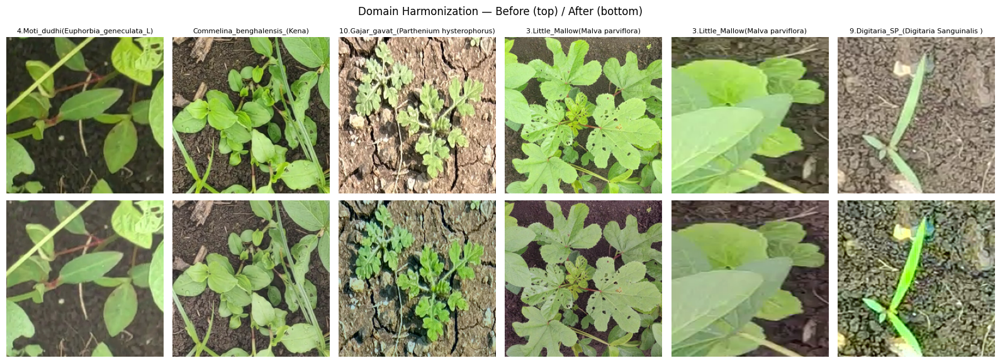

In [8]:
def lab_mean_std(img_rgb_uint8):
    """img_rgb_uint8: HxWx3 uint8 RGB numpy array."""
    import cv2
    lab = cv2.cvtColor(img_rgb_uint8, cv2.COLOR_RGB2LAB).astype(np.float32)
    return lab.mean(axis=(0, 1)), lab.std(axis=(0, 1)) + 1e-6


def build_reference_stats(subset, sample_size=400, seed=SEED):
    """Reference LAB stats computed ONLY from the training subset."""
    rng = pyrandom.Random(seed)
    idxs = list(range(len(subset)))
    sample_idxs = rng.sample(idxs, min(sample_size, len(idxs)))
    means, stds = [], []
    for i in sample_idxs:
        img, _ = subset[i]
        arr = np.array(img.convert("RGB"))
        m, s = lab_mean_std(arr)
        means.append(m)
        stds.append(s)
    return np.mean(means, axis=0), np.mean(stds, axis=0)


print("Computing shared color-reference statistics from the TRAINING split only...")
REF_LAB_MEAN, REF_LAB_STD = build_reference_stats(train_subset)
print("Reference LAB mean:", REF_LAB_MEAN, " std:", REF_LAB_STD)


class ReinhardHarmonize:
    """Deterministic torchvision-style transform: shifts a PIL image's LAB color
    statistics toward the shared reference. No randomness — same output every call,
    so it's safe to use on train, val AND test images."""
    def __init__(self, ref_mean, ref_std):
        self.ref_mean = ref_mean
        self.ref_std = ref_std

    def __call__(self, pil_img):
        import cv2
        arr = np.array(pil_img.convert("RGB"))
        lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB).astype(np.float32)
        src_mean, src_std = lab.mean(axis=(0, 1)), lab.std(axis=(0, 1)) + 1e-6
        lab = (lab - src_mean) / src_std * self.ref_std + self.ref_mean
        lab = np.clip(lab, 0, 255).astype(np.uint8)
        rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
        return Image.fromarray(rgb)


harmonize = ReinhardHarmonize(REF_LAB_MEAN, REF_LAB_STD)

# --- quick visual sanity check: a few train images, before vs after harmonization ---
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
sample_show_idxs = pyrandom.sample(range(len(train_subset)), 6)
for j, idx in enumerate(sample_show_idxs):
    img, label = train_subset[idx]
    axes[0, j].imshow(img); axes[0, j].set_title(class_names[label], fontsize=8); axes[0, j].axis('off')
    axes[1, j].imshow(harmonize(img)); axes[1, j].axis('off')
axes[0, 0].set_ylabel('Original', fontsize=10)
axes[1, 0].set_ylabel('Harmonized', fontsize=10)
plt.suptitle('Domain Harmonization — Before (top) / After (bottom)')
plt.tight_layout()
plt.savefig('harmonization_preview.png', dpi=150)
plt.show()

## 5. Per-Class Imbalance Analysis

Counts images per class **within the training split only** (val/test keep their natural, imbalanced
distribution — they must reflect what the model will face). Classes below `IMBALANCE_TARGET_FRACTION` of
the largest class are flagged as **rare**; every evaluation below reports recall on them separately, because
overall accuracy is dominated by the big classes.

Training-set image counts per class:
4.Moti_dudhi(Euphorbia_geneculata_L)              2110
3.Little_Mallow(Malva parviflora)                 1470
Commelina_benghalensis_(Kena)                     1315
5.Obscure_morning _glory(Ipomoea obscura)         1127
9.Digitaria_SP_(Digitaria Sanguinalis )           1083
10.Gajar_gavat_(Parthenium hysterophorus)         1072
14.Dwarf_cassia_(Chamaecrista pumila)              923
1..Lavhala_(Cyperus_Rotundus)                      793
7.Bilayat_(Mexicana_Argemone)                      609
2.Lamber_Quarter_plant(Chenopodium )               591
13.Harali_(Cynodon_dactylon)                       510
6.Asian_Pigeonwings_(Clitoria Ternatea)            476
12.Sicklepod_(Senna obtusifolia)                   460
8.Choti_dudhi_(Euphorbia_hirta)                    409
15.Punarnava _(Boerhaavia diffusa)                 384
W_CL_06_Ipomoea aquatic                            354
W_CL_07_Marsilea minuta                            215
11.Graceful_Sandmart_(Euphor

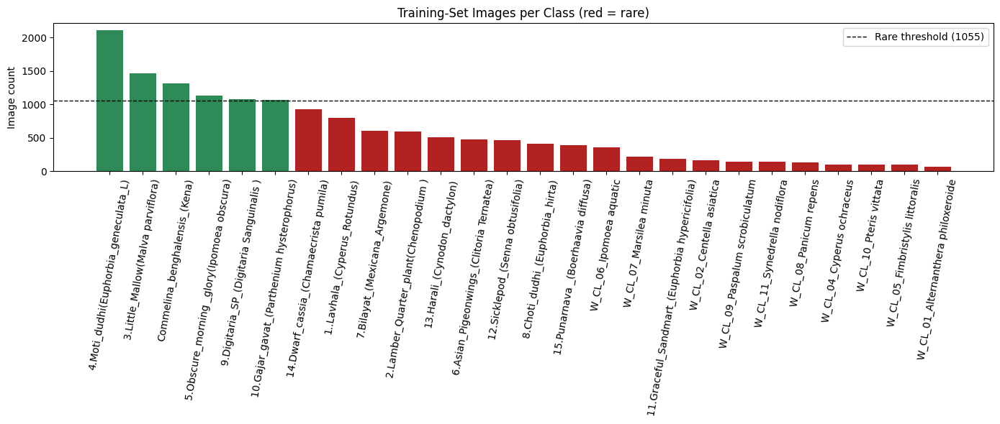

In [9]:
train_labels = [full_dataset.targets[i] for i in train_indices]
class_counts = pd.Series(train_labels).value_counts().sort_index()
class_counts.index = [class_names[i] for i in class_counts.index]
class_counts = class_counts.sort_values(ascending=False)

print("Training-set image counts per class:")
print(class_counts)

max_count = class_counts.max()
IMBALANCE_TARGET_FRACTION = 0.5   # classes below 50% of the majority count are flagged "rare"
target_count = int(max_count * IMBALANCE_TARGET_FRACTION)

rare_classes = class_counts[class_counts < target_count].index.tolist()
print(f"\nLargest class: {class_counts.idxmax()} ({max_count} images), smallest: {class_counts.idxmin()} ({class_counts.min()})")
print(f"Imbalance ratio (largest / smallest): {max_count / class_counts.min():.1f}x")
print(f"{len(rare_classes)} of {num_classes} classes are below {IMBALANCE_TARGET_FRACTION:.0%} of the majority ({target_count} images) -> 'rare'")

fig, ax = plt.subplots(figsize=(14, 6))
bar_colors = ['#B22222' if c in rare_classes else '#2E8B57' for c in class_counts.index]
ax.bar(class_counts.index, class_counts.values, color=bar_colors)
ax.axhline(target_count, color='black', linestyle='--', linewidth=1, label=f'Rare threshold ({target_count})')
ax.set_title('Training-Set Images per Class (red = rare)')
ax.set_ylabel('Image count'); ax.tick_params(axis='x', rotation=80); ax.legend()
plt.tight_layout(); plt.savefig('class_imbalance.png', dpi=150); plt.show()

## 5b. Duplicate Check — Is the Test Set Really Unseen?

The split is random per image. If a dataset contains near-identical photos (the same plant shot twice, a resized
or re-saved copy), one can land in training and its twin in test, which makes test accuracy look better than it
is. This cell checks for that **before any training**.

- Every image gets a **64-bit perceptual hash (dHash).** The hash does not change when an image is resized or
  re-compressed, but does change when the photo content changes.
- For each validation and test image, the **closest training image** is found. A distance of **0** means an exact
  visual copy; **≤ `DUP_HAMMING` (4)** means a near-duplicate.
- The result is broken down by source dataset and by class, and the closest pairs are shown, so you can see whether
  they really are the same photo.
- Nothing is removed from training. Instead, Section 17 scores every model again on the **duplicate-free** test
  images. If the two scores differ a lot, report the duplicate-free one.

Hashed 21,464 images in 42s

  val:   2.0% exact copies of a training image,   3.9% near-duplicates (distance <= 4)
 test:   1.9% exact copies of a training image,   3.6% near-duplicates (distance <= 4)

  Dataset 1 (Rice Field BD): 10.2% of 343 test images have a near-duplicate in training
  Dataset 2 (Individual Weed Species): 2.8% of 2,878 test images have a near-duplicate in training

Classes with the highest share of near-duplicated test images (%):
W_CL_02_Centella asiatica                    20.0
W_CL_10_Pteris vittata                       17.6
1..Lavhala_(Cyperus_Rotundus)                15.2
W_CL_09_Paspalum scrobiculatum               13.5
10.Gajar_gavat_(Parthenium hysterophorus)    13.3
W_CL_05_Fimbristylis littoralis              10.5
W_CL_04_Cyperus ochraceus                     5.9
Commelina_benghalensis_(Kena)                 5.0

Duplicate-free test set: 3,104 of 3,221 images (scored in Section 17)


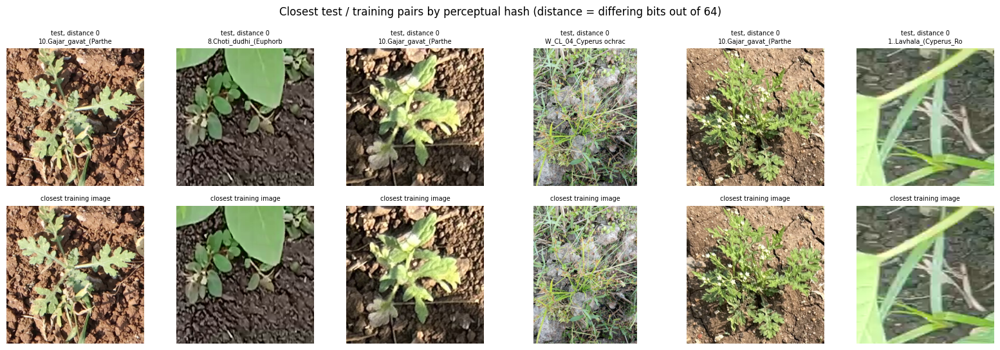

In [10]:
from concurrent.futures import ThreadPoolExecutor


def dhash(path, size=8):
    # 64-bit difference hash: robust to resizing / re-compression, changes when the photo content changes
    with Image.open(path) as im:
        g = np.asarray(im.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).ravel()).view(">u8")[0]


POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def nearest_hamming(query, ref, chunk=256):
    # distance to (and index of) the closest hash in ref, for every hash in query
    ref8 = ref.astype(">u8").view(np.uint8).reshape(-1, 8)
    dist, idx = np.empty(len(query), np.int32), np.empty(len(query), np.int64)
    for s in range(0, len(query), chunk):
        q8 = query[s:s + chunk].astype(">u8").view(np.uint8).reshape(-1, 1, 8)
        d = POPCOUNT[np.bitwise_xor(q8, ref8[None])].sum(-1, dtype=np.int32)
        dist[s:s + chunk], idx[s:s + chunk] = d.min(1), d.argmin(1)
    return dist, idx


t0 = time.time()
HASHES = {}
with ThreadPoolExecutor(max_workers=8) as ex:
    for split, idxs in (("train", train_indices), ("val", val_indices), ("test", test_indices)):
        HASHES[split] = np.array(list(ex.map(lambda i: dhash(full_dataset.samples[i][0]), idxs)), dtype=">u8")
test_d, test_nn = nearest_hamming(HASHES["test"], HASHES["train"])
val_d, _ = nearest_hamming(HASHES["val"], HASHES["train"])
TEST_CLEAN_MASK = test_d > DUP_HAMMING   # aligned with the test loader order (test_indices, no shuffling)
print(f"Hashed {sum(len(v) for v in HASHES.values()):,} images in {time.time() - t0:.0f}s\n")
for name, d in (("val", val_d), ("test", test_d)):
    print(f"{name:>5}: {np.mean(d == 0):6.1%} exact copies of a training image, "
          f"{np.mean(d <= DUP_HAMMING):6.1%} near-duplicates (distance <= {DUP_HAMMING})")

test_src = np.array([os.path.basename(full_dataset.samples[i][0]).split("__", 1)[0] for i in test_indices])
test_y = np.array([full_dataset.targets[i] for i in test_indices])
dup = ~TEST_CLEAN_MASK
print()
for tag, label in (("d1", "Dataset 1 (Rice Field BD)"), ("d2", "Dataset 2 (Individual Weed Species)")):
    m = test_src == tag
    if m.any():
        print(f"  {label}: {dup[m].mean():.1%} of {m.sum():,} test images have a near-duplicate in training")
per_class = pd.Series({class_names[c]: dup[test_y == c].mean() for c in range(num_classes)}).sort_values(ascending=False)
print("\nClasses with the highest share of near-duplicated test images (%):")
print((per_class.head(8) * 100).round(1).to_string())
print(f"\nDuplicate-free test set: {TEST_CLEAN_MASK.sum():,} of {len(TEST_CLEAN_MASK):,} images (scored in Section 17)")

order = np.argsort(test_d)[:6]   # the closest test/train pairs
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
for j, k in enumerate(order):
    for r, idx in enumerate((test_indices[k], train_indices[test_nn[k]])):
        axes[r, j].imshow(Image.open(full_dataset.samples[idx][0]).convert("RGB"))
        axes[r, j].axis("off")
    axes[0, j].set_title(f"test, distance {test_d[k]}\n{class_names[test_y[k]][:22]}", fontsize=7)
    axes[1, j].set_title("closest training image", fontsize=7)
plt.suptitle("Closest test / training pairs by perceptual hash (distance = differing bits out of 64)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "duplicate_pairs.png"), dpi=120); plt.show()

## 6. Transforms & Dataset Wrapper

Real training images: harmonize → random resized crop, flips, affine, color jitter, blur.
Val/test: harmonize + resize only. The traditional augmentation is applied **every time an image is drawn**,
so a rare image drawn many times by the weighted sampler is never pixel-identical.

In [11]:
def get_train_transform(img_size):
    return transforms.Compose([
        harmonize,
        transforms.RandomResizedCrop(img_size, scale=(0.6, 1.0), ratio=(0.75, 1.3333333333333333)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.8, 1.2), shear=10),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        transforms.GaussianBlur(kernel_size=3),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


def get_eval_transform(img_size):
    return transforms.Compose([
        harmonize,
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


class TransformedSubset(Dataset):
    """Wraps a torch Subset (of the untransformed ImageFolder) with a chosen transform."""
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        return self.transform(img), label

## 7. Model — MobileNetV3-Small

ImageNet-pretrained `torchvision` MobileNetV3-Small, classifier head replaced with a 26-way linear layer.

In [12]:
MODEL_CONFIGS = {
    "mobilenetv3": {"display": "MobileNetV3-Small", "img_size": 224},
}


def build_model(name: str, num_classes: int) -> nn.Module:
    name = name.lower()
    if name != "mobilenetv3":
        raise ValueError(f"Unknown model name: {name} (this notebook only builds 'mobilenetv3')")
    weights = models.MobileNet_V3_Small_Weights.DEFAULT
    model = models.mobilenet_v3_small(weights=weights)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model.to(device)


def model_stats(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    tmp_path = "/tmp/_tmp_model_size.pt"
    torch.save(model.state_dict(), tmp_path)
    size_mb = os.path.getsize(tmp_path) / (1024 * 1024)
    os.remove(tmp_path)
    return total_params, trainable_params, size_mb

## 8. Train / Evaluate Loop

Adam (weight decay 1e-4) on all trainable parameters, `ReduceLROnPlateau` on the (unweighted) validation loss,
checkpoint = epoch with the best validation accuracy, early stopping after `EARLY_STOP_PATIENCE` epochs without a
new best.

**Resumable training.** After every epoch, `<id>_state.pt` stores the weights, optimizer and scheduler state, the
history and the best weights. When it exists, training continues at the next epoch exactly where it stopped (with a
new random seed for the resumed epochs). `fit_resumable` adds the "already finished?" logic, and `check_time` stops
before an epoch that would not finish within `TIME_BUDGET_HOURS`.

In [13]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


class TimeBudgetExceeded(Exception):
    pass


TIME_STATUS = {"out_of_time": False}
EPOCH_SECONDS = {"last": 600.0}   # duration of the latest epoch; first guess 10 min


def time_left_s():
    return TIME_BUDGET_HOURS * 3600 - (time.time() - SESSION_START)


def check_time(reserve_s=1200):
    # Raise before starting an epoch that would not finish (with a reserve for evaluation and saving) in time.
    if TIME_STATUS["out_of_time"] or time_left_s() < 1.2 * EPOCH_SECONDS["last"] + reserve_s:
        TIME_STATUS["out_of_time"] = True
        raise TimeBudgetExceeded(f"time budget reached ({(time.time() - SESSION_START) / 3600:.1f} h used of "
                                 f"{TIME_BUDGET_HOURS:g} h) — stopping here; the next version continues")


def train_model(model, model_name, train_loader, val_loader, num_epochs=10, lr=1e-3,
                class_weights=None, weight_decay=1e-4, state_path=None, state_tag=None, warm_start=None,
                early_stop_patience=None):
    params = [p for p in model.parameters() if p.requires_grad]
    total, trainable = count_params(model)
    criterion = nn.CrossEntropyLoss(weight=class_weights)   # training loss (optionally class-weighted)
    val_criterion = nn.CrossEntropyLoss()                   # validation loss stays unweighted
    optimizer = optim.Adam(params, lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    best_acc = 0.0
    best_wts = copy.deepcopy(model.state_dict())
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': []}

    print(f"\n{'='*60}\nTraining: {model_name}\n{'='*60}")
    print(f"Trainable params: {trainable:,} / {total:,} ({trainable / total:.1%})   frozen: {total - trainable:,}")

    start_epoch, prev_elapsed = 0, 0.0
    if state_path and os.path.exists(state_path):
        st = torch.load(state_path, map_location=device, weights_only=False)
        model.load_state_dict(st["model"])
        optimizer.load_state_dict(st["optimizer"])
        scheduler.load_state_dict(st["scheduler"])
        history, best_acc, best_wts = st["history"], st["best_acc"], st["best_wts"]
        start_epoch, prev_elapsed = st["epoch"], st["elapsed"]
        print(f"[resume] continuing after epoch {start_epoch} (weights, optimizer and LR schedule restored)")
    elif warm_start is not None:   # older checkpoint: best weights + history only
        history = copy.deepcopy(warm_start["history"])
        start_epoch, prev_elapsed = len(history["val_acc"]), warm_start["elapsed"]
        best_acc, best_wts = max(history["val_acc"]), copy.deepcopy(model.state_dict())
        if history.get("lr"):
            for group in optimizer.param_groups:   # keep each group's ratio to the main learning rate
                group["lr"] *= history["lr"][-1] / lr
        print(f"[resume] continuing after epoch {start_epoch} from the saved best weights "
              f"(LR {optimizer.param_groups[0]['lr']:.1e}; optimizer moments start fresh)")
    if start_epoch:
        # new randomness for the resumed epochs, instead of replaying epoch 1's augmentation / sampling order
        torch.manual_seed(TRAIN_SEED + start_epoch)
        if getattr(train_loader.sampler, "generator", None) is not None:
            train_loader.sampler.generator.manual_seed(TRAIN_SEED + start_epoch)
    if start_epoch >= num_epochs:
        print(f"Already trained {start_epoch} epochs (asked for {num_epochs}) — nothing to do")
    since = time.time()

    stopped_early = False
    for epoch in range(start_epoch, num_epochs):
        if early_stop_patience and history["val_acc"]:
            since_best = len(history["val_acc"]) - 1 - int(np.argmax(history["val_acc"]))
            if since_best >= early_stop_patience:
                print(f"Early stopping: no val_acc improvement for {since_best} epochs "
                      f"(best epoch {len(history['val_acc']) - since_best})")
                stopped_early = True
                break
        check_time()   # the previous epoch's state is already saved, so stopping here loses nothing
        epoch_t0 = time.time()
        model.train()
        running_loss, running_corrects, total_n = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)
            total_n += inputs.size(0)
        train_loss = running_loss / total_n
        train_acc = (running_corrects.float() / total_n).item()

        model.eval()
        running_loss, running_corrects, total_n = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = val_criterion(outputs, labels)
                _, preds = torch.max(outputs, 1)
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                total_n += inputs.size(0)
        val_loss = running_loss / total_n
        val_acc = (running_corrects.float() / total_n).item()

        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['lr'].append(optimizer.param_groups[0]['lr'])

        if val_acc > best_acc:
            best_acc = val_acc
            best_wts = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch+1}/{num_epochs}  train_loss={train_loss:.4f} train_acc={train_acc:.4f}  "
              f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

        if state_path:   # written to a temp file first, so a crash mid-save never corrupts the last good state
            torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                            scheduler=scheduler.state_dict(), history=history, best_acc=best_acc,
                            best_wts=best_wts, epoch=epoch + 1, elapsed=prev_elapsed + time.time() - since,
                            depends_on=state_tag), state_path + ".tmp")
            os.replace(state_path + ".tmp", state_path)
        EPOCH_SECONDS["last"] = time.time() - epoch_t0

    elapsed = prev_elapsed + time.time() - since
    print(f"Training complete in {elapsed//60:.0f}m {elapsed%60:.0f}s  best val_acc={best_acc:.4f}")
    model.load_state_dict(best_wts)
    history["stopped_early"] = stopped_early
    return model, history, best_acc, elapsed


@torch.no_grad()
def evaluate_logits_model(model, loader):
    model.eval()
    y_true, y_pred, y_probs = [], [], []
    times = []
    for inputs, labels in loader:
        inputs = inputs.to(device)
        t0 = time.time()
        outputs = model(inputs)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        times.append((time.time() - t0) * 1000 / inputs.size(0))
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(probs, dim=1)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(preds.cpu().numpy().tolist())
        y_probs.extend(probs.cpu().numpy().tolist())
    return y_true, y_pred, y_probs, float(np.mean(times))


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f)


def load_json(path):
    with open(path) as f:
        return json.load(f)


UPSTREAM_TRAINED = set()   # stages trained in this session; results built on their old weights are stale


def fit_resumable(tag, model, display, train_loader, val_loader, epochs, lr, meta_path,
                  class_weights=None, depends_on=None, **train_kwargs):
    '''Trains `model` to `epochs` epochs in total, reusing whatever an earlier run saved in OUT_DIR.

    Files: <tag>.pt (best weights), <tag>_state.pt (per-epoch training state), meta_path (history + results).
    depends_on = (upstream name, token): if the upstream stage changed since this model was trained, it restarts
    from epoch 0. Returns (model, record, trained_now).'''
    ckpt = os.path.join(OUT_DIR, f"{tag}.pt")
    state_path = os.path.join(OUT_DIR, f"{tag}_state.pt")
    token = depends_on[1] if depends_on else None

    prev = load_json(meta_path) if (RESUME and os.path.exists(meta_path) and os.path.exists(ckpt)) else None
    if prev is not None and depends_on is not None:
        # older metadata has no token: treat it as stale only if its upstream was retrained in this session
        stale = prev["depends_on"] != token if "depends_on" in prev else depends_on[0] in UPSTREAM_TRAINED
        if stale:
            print(f"[{tag}] '{depends_on[0]}' changed since this model was trained -> training from epoch 0")
            for path in (ckpt, meta_path):
                os.remove(path)
            prev = None
    if os.path.exists(state_path) and (
            not RESUME or torch.load(state_path, map_location="cpu", weights_only=False).get("depends_on") != token):
        os.remove(state_path)

    done = len(prev["history"]["val_acc"]) if prev else 0
    if prev is not None and (done >= epochs or prev.get("early_stopped")):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        how = "early-stopped (converged)" if prev.get("early_stopped") else f"asked for {epochs}"
        print(f"[resume] {tag}: already trained for {done} epochs, {how} -> loaded, not retrained")
        return model, prev, False

    warm = None
    if prev is not None and not os.path.exists(state_path):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        warm = dict(history=prev["history"], elapsed=prev["train_time_s"])
    model, hist, best, secs = train_model(model, display, train_loader, val_loader, num_epochs=epochs, lr=lr,
                                          class_weights=class_weights, state_path=state_path, state_tag=token,
                                          warm_start=warm, **train_kwargs)
    torch.save(model.state_dict(), ckpt)
    early_stopped = bool(hist.pop("stopped_early", False))
    return model, dict(history=hist, best_val_acc=best, train_time_s=secs, depends_on=token,
                       early_stopped=early_stopped), True

---
## 9. Imbalance Strategy (Decided Earlier)

The training set is heavily imbalanced: the largest class has 2,110 images and the smallest 65 (32.5×), and 20 of 26
classes are "rare". Five strategies were compared earlier (MobileNetV3-Small, 30 epochs, seed 42):

| Strategy | Val macro-F1 | Rare recall | Test macro-F1 |
|---|---|---|---|
| Diffusion synthetic images | rejected: FID 389.8 (threshold 100) | — | — |
| A — Baseline | 93.60 | 92.87 | 93.13 |
| B — Class-weighted loss | 93.73 | 93.97 | 92.71 |
| **C — Weighted sampler** | **94.37** | **94.40** | **93.94** |
| D — B + C | 93.67 | 93.91 | 92.99 |

**C (weighted sampler)** is best on every metric, so every model uses it. Rare-class images are drawn more
often (probability ∝ count^-0.5), and each draw gets fresh random augmentation, so repeated images are never
pixel-identical.

In [14]:
VARIANTS = {
    "A_baseline":            dict(loss_weights=False, sampler=False),
    "B_class_weight":        dict(loss_weights=True,  sampler=False),
    "C_weighted_sampler":    dict(loss_weights=False, sampler=True),
    "D_weight_plus_sampler": dict(loss_weights=True,  sampler=True),
}
BEST_STRATEGY = "C_weighted_sampler"
STRATEGY_CFG = VARIANTS[BEST_STRATEGY]
print(f"Imbalance strategy: {BEST_STRATEGY} {STRATEGY_CFG}")

Imbalance strategy: C_weighted_sampler {'loss_weights': False, 'sampler': True}


## 10. Merged-Dataset Loaders for the Chosen Strategy

`make_class_weights`, `make_weighted_sampler` and the rare/tail class lists, wrapped in
`make_merged_train_loader`, which builds the training loader and loss weights for whatever `STRATEGY_CFG` says.
Validation and test loaders never use a sampler or augmentation — they always measure the natural, imbalanced
distribution.

In [15]:
train_targets = np.array([full_dataset.targets[i] for i in train_indices])
train_class_n = np.bincount(train_targets, minlength=num_classes).astype(np.float64)
assert (train_class_n > 0).all()
rare_idx_list = sorted(full_dataset.class_to_idx[c] for c in rare_classes)
tail_idx_list = [c for c in range(num_classes) if train_class_n[c] < TAIL_MAX_IMAGES]
print(f"{len(rare_idx_list)} rare classes, {len(tail_idx_list)} tail classes (< {TAIL_MAX_IMAGES} train images)")


def make_class_weights(counts, power):
    '''Loss weights ~ count^-power, rescaled so the average per-SAMPLE weight is 1 (keeps LR scale comparable).'''
    w = counts ** (-power)
    return w * counts.sum() / (w * counts).sum()


def make_weighted_sampler(targets, counts, power, num_samples, seed):
    '''Sample i is drawn with probability ~ count[class_i]^-power. Epoch length is unchanged.'''
    sample_w = torch.as_tensor((counts ** (-power))[targets], dtype=torch.double)
    g = torch.Generator().manual_seed(seed)
    return WeightedRandomSampler(sample_w, num_samples=num_samples, replacement=True, generator=g)


def set_all_seeds(s):
    torch.manual_seed(s); np.random.seed(s); pyrandom.seed(s)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(s)


class_w_np = make_class_weights(train_class_n, IMBALANCE_POWER)


def make_merged_train_loader(cfg, seed):
    train_ds = TransformedSubset(train_subset, get_train_transform(IMG_SIZE))
    sampler = (make_weighted_sampler(train_targets, train_class_n, IMBALANCE_POWER, len(train_ds), seed)
               if cfg["sampler"] else None)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=(sampler is None), sampler=sampler,
                        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
    cw = torch.tensor(class_w_np, dtype=torch.float32, device=device) if cfg["loss_weights"] else None
    return loader, cw


merged_val_loader  = DataLoader(TransformedSubset(val_subset,  get_eval_transform(IMG_SIZE)),
                                batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
merged_test_loader = DataLoader(TransformedSubset(test_subset, get_eval_transform(IMG_SIZE)),
                                batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f"Train loader strategy: {BEST_STRATEGY}   val: {len(val_subset)} images   test: {len(test_subset)} images")

20 rare classes, 9 tail classes (< 200 train images)
Train loader strategy: C_weighted_sampler   val: 3219 images   test: 3221 images


---
# Part 1 — Models and Training

## 11. WeedNet-v4 (W2 proposed, W1 ablation)

```
input 3×224×224
   ├── imagenet_stem   MobileNetV3-Small features[0:9], ImageNet weights, trainable        190.5 K params  -> 48×14×14
   ├── domain_blocks   3 MobileNetV3-style bottlenecks (SE, h-swish), random init          233.5 K params
   │                   + 1×1 conv → 320, Hardswish                                                         -> 320×7×7
   └── head
        W2 (proposed): QKV attention head                                                  117.5 K params
                       1×1 conv 320→128 → 49 tokens + learnable [CLS] token + position embedding
                       LayerNorm → Q, K, V (4 heads × 32) → softmax(QKᵀ/√32)·V → residual
                       LayerNorm → Dropout 0.2 → Linear(128 → 26) on the [CLS] token   TOTAL ≈ 541.5 K params
        W1 (ablation): global average pool → FC 320→256 → Hardswish → Dropout 0.2 → FC 256→26
                                                                         88.9 K params  TOTAL ≈ 512.8 K params
```

The [CLS] token's attention over the 49 positions is kept in `model.head.last_attn` and used as the explanation map
in Part 3. `count_macs` counts the multiply-accumulate operations of convolutions and linear layers.

In [16]:
def _make_divisible(v, divisor=8):
    new_v = max(divisor, int(v + divisor / 2) // divisor * divisor)
    return new_v + divisor if new_v < 0.9 * v else new_v


class SqueezeExcite(nn.Module):
    '''Channel attention: global pool -> bottleneck -> hard-sigmoid gate per channel.'''
    def __init__(self, channels, reduction=4):
        super().__init__()
        squeeze = _make_divisible(channels // reduction)
        self.fc1 = nn.Conv2d(channels, squeeze, 1)
        self.act = nn.ReLU(inplace=True)
        self.fc2 = nn.Conv2d(squeeze, channels, 1)
        self.gate = nn.Hardsigmoid(inplace=True)

    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        return x * self.gate(self.fc2(self.act(self.fc1(s))))


class InvertedResidualV3(nn.Module):
    '''MobileNetV3 bottleneck: 1x1 expand -> kxk depthwise -> (SE) -> 1x1 project, residual when shapes match.'''
    def __init__(self, in_ch, exp_ch, out_ch, kernel, stride, use_se=True):
        super().__init__()
        layers = []
        if exp_ch != in_ch:
            layers += [nn.Conv2d(in_ch, exp_ch, 1, bias=False), nn.BatchNorm2d(exp_ch), nn.Hardswish(inplace=True)]
        layers += [nn.Conv2d(exp_ch, exp_ch, kernel, stride, kernel // 2, groups=exp_ch, bias=False),
                   nn.BatchNorm2d(exp_ch), nn.Hardswish(inplace=True)]
        if use_se:
            layers.append(SqueezeExcite(exp_ch))
        layers += [nn.Conv2d(exp_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch)]
        self.block = nn.Sequential(*layers)
        self.use_residual = stride == 1 and in_ch == out_ch

    def forward(self, x):
        y = self.block(x)
        return x + y if self.use_residual else y


class AttentionHead(nn.Module):
    '''Classification head: multi-head self-attention (Q/K/V) over the HxW feature map plus a [CLS] token.'''
    def __init__(self, in_ch, num_classes, hw, dim=ATTN_DIM, heads=ATTN_HEADS, dropout=0.2):
        super().__init__()
        assert dim % heads == 0
        self.heads, self.d = heads, dim // heads
        self.reduce = nn.Conv2d(in_ch, dim, 1)                         # 320 -> 128 channels = token size
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))                 # learnable summary token
        self.pos = nn.Parameter(torch.zeros(1, hw[0] * hw[1] + 1, dim)) # attention alone is position-blind
        self.norm1 = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, dim * 3)                              # Query, Key and Value in one layer
        self.proj = nn.Linear(dim, dim)
        self.norm2 = nn.LayerNorm(dim)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(dim, num_classes)
        self.last_attn = None                                           # (batch, heads, tokens, tokens), for plots

    def forward(self, x):
        B = x.shape[0]
        t = self.reduce(x).flatten(2).transpose(1, 2)                   # (B, 49, dim): one token per position
        t = torch.cat([self.cls.expand(B, -1, -1), t], dim=1) + self.pos
        q, k, v = self.qkv(self.norm1(t)).reshape(B, -1, 3, self.heads, self.d).permute(2, 0, 3, 1, 4)
        attn = ((q @ k.transpose(-2, -1)) / self.d ** 0.5).softmax(dim=-1)   # (B, heads, 50, 50)
        self.last_attn = attn.detach()
        t = t + self.proj((attn @ v).transpose(1, 2).reshape(B, -1, self.heads * self.d))
        return self.fc(self.drop(self.norm2(t[:, 0])))                  # classify the [CLS] token


DOMAIN_BLOCK_SPEC = [   # (expand channels, out channels, kernel, stride, SE)
    (192, 80, 5, 2, True),
    (240, 80, 5, 1, True),
    (240, 96, 3, 1, True),
]
LAST_CONV_CH = 320
HEAD_HIDDEN = 256       # plain head (W1) only


class WeedNetV4(nn.Module):
    def __init__(self, num_classes, attention_head=True, freeze_upto=FREEZE_UPTO):
        super().__init__()
        donor = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        self.imagenet_stem = nn.Sequential(*list(donor.features.children())[:freeze_upto])   # pretrained, trainable

        with torch.no_grad():
            ch = self.imagenet_stem.eval()(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).shape[1]
        blocks = []
        for exp_ch, out_ch, k, s, se in DOMAIN_BLOCK_SPEC:
            blocks.append(InvertedResidualV3(ch, exp_ch, out_ch, k, s, se))
            ch = out_ch
        blocks.append(nn.Sequential(nn.Conv2d(ch, LAST_CONV_CH, 1, bias=False),
                                    nn.BatchNorm2d(LAST_CONV_CH), nn.Hardswish(inplace=True)))
        self.domain_blocks = nn.Sequential(*blocks)

        if attention_head:
            with torch.no_grad():
                hw = tuple(self.domain_blocks.eval()(self.imagenet_stem(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))).shape[-2:])
            self.head = AttentionHead(LAST_CONV_CH, num_classes, hw)
        else:
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Linear(LAST_CONV_CH, HEAD_HIDDEN), nn.Hardswish(inplace=True),
                                      nn.Dropout(0.2), nn.Linear(HEAD_HIDDEN, num_classes))
        self._init_random(self.domain_blocks)
        self._init_random(self.head)
        self.train()

    @staticmethod
    def _init_random(module):
        for m in module.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02); nn.init.zeros_(m.bias)
            elif isinstance(m, AttentionHead):
                nn.init.trunc_normal_(m.cls, std=0.02); nn.init.trunc_normal_(m.pos, std=0.02)

    def forward(self, x):
        return self.head(self.domain_blocks(self.imagenet_stem(x)))


def describe_trainable(model):
    rows = []
    for name in ("imagenet_stem", "domain_blocks", "head"):
        part = getattr(model, name)
        n = sum(p.numel() for p in part.parameters())
        t = sum(p.numel() for p in part.parameters() if p.requires_grad)
        rows.append(dict(part=name, params=n, trainable=t, status="TRAIN" if t else "frozen"))
    print(pd.DataFrame(rows).to_string(index=False))


@torch.no_grad()
def count_macs(model, img_size=IMG_SIZE):
    '''Multiply-accumulate operations for one image (convolutions + linear layers; attention products excluded).'''
    macs = [0]

    def conv_hook(m, inp, out):
        macs[0] += (out.numel() // out.shape[0]) * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]

    def linear_hook(m, inp, out):
        macs[0] += (out.numel() // out.shape[-1]) // out.shape[0] * m.in_features * m.out_features

    hooks = [m.register_forward_hook(conv_hook) for m in model.modules() if isinstance(m, nn.Conv2d)]
    hooks += [m.register_forward_hook(linear_hook) for m in model.modules() if isinstance(m, nn.Linear)]
    was_training = model.training
    model.eval()
    model(torch.zeros(1, 3, img_size, img_size, device=next(model.parameters()).device))
    for h in hooks:
        h.remove()
    model.train(was_training)
    return macs[0] / 1e9


# ---- architecture summary ----
for label, attn in (("WeedNet-v4, attention head (W2)", True), ("WeedNet-v4, plain head (W1)", False)):
    _m = WeedNetV4(num_classes, attention_head=attn)
    print(f"{label}: {count_params(_m)[0]:,} params, {count_macs(_m):.3f} GMACs")
    describe_trainable(_m)
    print()
_ref = build_model("mobilenetv3", num_classes).cpu()
print(f"MobileNetV3-Small (M1): {count_params(_ref)[0]:,} params, {count_macs(_ref):.3f} GMACs")
del _m, _ref

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 152MB/s]


WeedNet-v4, attention head (W2): 541,506 params, 0.049 GMACs
         part  params  trainable status
imagenet_stem  190520     190520  TRAIN
domain_blocks  233456     233456  TRAIN
         head  117530     117530  TRAIN

WeedNet-v4, plain head (W1): 512,834 params, 0.044 GMACs
         part  params  trainable status
imagenet_stem  190520     190520  TRAIN
domain_blocks  233456     233456  TRAIN
         head   88858      88858  TRAIN

MobileNetV3-Small (M1): 1,544,506 params, 0.056 GMACs


## 12. Experiment Runner

Every model below goes through `run_experiment`, so all of them get the same treatment:
same seed, same train loader (weighted sampler), same val/test loaders, best epoch by validation accuracy.
After training it:

- saves the weights (`<id>.pt`), test predictions + probabilities (`<id>_preds.npz`) and metadata (`<id>_meta.json`);
- measures total/trainable parameters, size on disk, MACs, inference latency and training time;
- with `RESUME = True`, reloads a finished model instead of retraining it, and continues an unfinished or extended
  one from its last saved epoch (see `fit_resumable`, Section 8). Test predictions are recomputed whenever the
  model trained further.

In [17]:
EXPERIMENTS = {}   # model_id -> metadata dict
PREDICTIONS = {}   # model_id -> dict(y_true, y_pred, y_prob)


def run_experiment(model_id, display, pipeline, build_fn, epochs, lr, upstream_time_s=0.0, frozen_check=None,
                   depends_on=None, seed=None, **train_kwargs):
    seed = TRAIN_SEED if seed is None else seed
    meta_path = os.path.join(OUT_DIR, f"{model_id}_meta.json")
    pred_path = os.path.join(OUT_DIR, f"{model_id}_preds.npz")

    set_all_seeds(seed)
    model = build_fn().to(device)
    if hasattr(model, "domain_blocks"):
        describe_trainable(model)
    _, trainable = count_params(model)   # count before training (reflects this stage's freezing)

    loader, cw = make_merged_train_loader(STRATEGY_CFG, seed)   # cheap: only iterated if training is needed
    try:
        model, rec, trained_now = fit_resumable(model_id, model, f"{model_id} — {display}", loader, merged_val_loader,
                                                epochs, lr, meta_path, class_weights=cw, depends_on=depends_on,
                                                **train_kwargs)
    except TimeBudgetExceeded as e:
        print(f"[time] {model_id}: {e}")
        return None
    if not trained_now and os.path.exists(pred_path):
        meta = rec
    else:
        hist, best_val, secs = rec["history"], rec["best_val_acc"], rec["train_time_s"]
        y_t, y_p, y_prob, ms = evaluate_logits_model(model, merged_test_loader)
        v_t, v_p, _, _ = evaluate_logits_model(model, merged_val_loader)
        np.savez_compressed(pred_path, y_true=np.array(y_t), y_pred=np.array(y_p),
                            y_prob=np.array(y_prob, dtype=np.float32))
        total, _, size_mb = model_stats(model)
        meta = dict(display=display, pipeline=pipeline, epochs=len(hist["val_acc"]), lr=lr, strategy=BEST_STRATEGY,
                    history=hist, best_val_acc=best_val, depends_on=rec.get("depends_on"),
                    early_stopped=rec.get("early_stopped", False), max_epochs=epochs, seed=seed,
                    val_acc=accuracy_score(v_t, v_p), val_f1_macro=f1_score(v_t, v_p, average="macro"),
                    train_time_s=secs, upstream_time_s=upstream_time_s, ms_per_image=ms,
                    total_params=total, trainable_params=trainable, size_mb=size_mb, gmacs=count_macs(model))
        save_json(meta, meta_path)
        UPSTREAM_TRAINED.add(model_id)

    if frozen_check is not None:
        part_name, reference_state = frozen_check
        part_sd = getattr(model, part_name).state_dict()
        same = all(torch.equal(v.cpu(), reference_state[f"{part_name}.{k}"]) for k, v in part_sd.items())
        print(f"{model_id}: '{part_name}' unchanged by training: {same}")
        assert same

    data = np.load(pred_path)
    PREDICTIONS[model_id] = dict(y_true=data["y_true"], y_pred=data["y_pred"], y_prob=data["y_prob"])
    EXPERIMENTS[model_id] = meta
    print(f"{model_id}: val macro-F1={meta['val_f1_macro']:.4f}  "
          f"test acc={accuracy_score(data['y_true'], data['y_pred']):.4f}  "
          f"test macro-F1={f1_score(data['y_true'], data['y_pred'], average='macro'):.4f}")
    return model

## 12. Model Builders

Every comparison model is the standard ImageNet-pretrained architecture with only its last layer replaced by a
26-class layer; all layers are trained with the same protocol as WeedNet.

In [18]:
def build_shufflenet():
    m = models.shufflenet_v2_x0_5(weights=models.ShuffleNet_V2_X0_5_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m


def build_lcnet():
    import timm
    return timm.create_model("lcnet_050", pretrained=True, num_classes=num_classes)


def build_squeezenet():
    m = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.DEFAULT)
    final = nn.Conv2d(512, num_classes, kernel_size=1)
    nn.init.normal_(final.weight, mean=0.0, std=0.01)
    nn.init.zeros_(final.bias)
    m.classifier[1] = final
    m.num_classes = num_classes
    return m


def build_small_baseline():
    import timm
    return timm.create_model("mobilenetv3_small_050", pretrained=True, num_classes=num_classes)


FAMILIES = {   # display name, description, builder, extra training options
    "W2": ("WeedNet-v4 + QKV head (proposed)", "ImageNet stem (trainable) + random blocks + QKV attention head",
           lambda: WeedNetV4(num_classes, attention_head=True), {}),
    "W1": ("WeedNet-v4, plain head (ablation)", "ImageNet stem (trainable) + random blocks + pooled FC head",
           lambda: WeedNetV4(num_classes, attention_head=False), {}),
    "B1": ("MobileNetV3-Small 0.5x", "timm mobilenetv3_small_050, all layers fine-tuned", build_small_baseline, {}),
    "M1": ("MobileNetV3-Small 1.0x", "torchvision mobilenet_v3_small, all layers fine-tuned",
           lambda: build_model("mobilenetv3", num_classes), {}),
    "S1": ("ShuffleNetV2 0.5x", "torchvision shufflenet_v2_x0_5, all layers fine-tuned", build_shufflenet, {}),
    "L1": ("PP-LCNet 0.5x", "timm lcnet_050, all layers fine-tuned", build_lcnet, {}),
    "Q1": ("SqueezeNet 1.1", "torchvision squeezenet1_1, all layers fine-tuned", build_squeezenet, {}),
}

_w2_params = count_params(WeedNetV4(num_classes, attention_head=True))[0]
size_rows = []
for fam in FAMILIES:
    _m = FAMILIES[fam][2]().cpu()
    n = count_params(_m)[0]
    size_rows.append(dict(id=fam, model=FAMILIES[fam][0], params=n, params_vs_W2=n / _w2_params, gmacs=count_macs(_m)))
    del _m
size_df = pd.DataFrame(size_rows).set_index("id")
print(size_df.to_string(formatters={"params": "{:,}".format, "params_vs_W2": "{:.2f}x".format,
                                    "gmacs": "{:.3f}".format}))

model.safetensors: reconstructing file:   0%|          |  0.00B / 6.42MB            

model.safetensors: downloading bytes:           |  0.00B            

Downloading: "https://download.pytorch.org/models/shufflenetv2_x0.5-f707e7126e.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x0.5-f707e7126e.pth


100%|██████████| 5.28M/5.28M [00:00<00:00, 116MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B / 7.56MB            

model.safetensors: downloading bytes:           |  0.00B            

Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 114MB/s]

                                model    params params_vs_W2 gmacs
id                                                                
W2   WeedNet-v4 + QKV head (proposed)   541,506        1.00x 0.049
W1  WeedNet-v4, plain head (ablation)   512,834        0.95x 0.044
B1             MobileNetV3-Small 0.5x   594,874        1.10x 0.023
M1             MobileNetV3-Small 1.0x 1,544,506        2.85x 0.056
S1                  ShuffleNetV2 0.5x   368,442        0.68x 0.039
L1                      PP-LCNet 0.5x   633,162        1.17x 0.043
Q1                     SqueezeNet 1.1   735,834        1.36x 0.265


## 13. Source-Test Setup (Single-Source Models)

Almost every class comes from only one of the two datasets, which differ in camera and background. To measure species
recognition without a possible "which dataset is it?" cue, W1 is also trained on each dataset alone (same images,
same split; *Commelina* kept in each with that source's images; labels renumbered). Scored in Section 20.

In [19]:
def sample_source(i):
    return os.path.basename(full_dataset.samples[i][0]).split("__", 1)[0]


class RelabeledSubset(Dataset):
    '''Images of full_dataset at `indices`, transformed, with labels renumbered by `label_map`.'''
    def __init__(self, indices, transform, label_map):
        self.indices, self.transform, self.label_map = indices, transform, label_map

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, k):
        img, y = full_dataset[self.indices[k]]
        return self.transform(img), self.label_map[y]


SOURCE_SPLITS = {}
for src, label in (("d1", "Dataset 1 (Rice Field BD)"), ("d2", "Dataset 2 (Individual Weed Species)")):
    split = {name: [i for i in idxs if sample_source(i) == src]
             for name, idxs in (("train", train_indices), ("val", val_indices), ("test", test_indices))}
    classes = sorted({full_dataset.targets[i] for i in split["train"] + split["val"] + split["test"]})
    SOURCE_SPLITS[src] = dict(split, classes=classes, label_map={c: k for k, c in enumerate(classes)}, label=label)
    print(f"{label}: {len(classes)} classes | train {len(split['train']):,}  val {len(split['val']):,}  "
          f"test {len(split['test']):,}")

SOURCE_RESULTS = {}


def run_source_experiment(src):
    S = SOURCE_SPLITS[src]
    tag, n_cls = f"SRC_{src}", len(S["classes"])
    meta_path, pred_path = os.path.join(OUT_DIR, f"{tag}_meta.json"), os.path.join(OUT_DIR, f"{tag}_preds.npz")
    set_all_seeds(TRAIN_SEED)
    model = WeedNetV4(n_cls, attention_head=False).to(device)

    tr_targets = np.array([S["label_map"][full_dataset.targets[i]] for i in S["train"]])
    counts = np.maximum(np.bincount(tr_targets, minlength=n_cls), 1).astype(np.float64)
    train_ds = RelabeledSubset(S["train"], get_train_transform(IMG_SIZE), S["label_map"])
    sampler = make_weighted_sampler(tr_targets, counts, IMBALANCE_POWER, len(train_ds), TRAIN_SEED)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS,
                              pin_memory=(device.type == "cuda"))
    eval_loader = lambda part: DataLoader(RelabeledSubset(S[part], get_eval_transform(IMG_SIZE), S["label_map"]),
                                          batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    try:
        model, rec, trained_now = fit_resumable(
            tag, model, f"{tag} — W1 trained on {S['label']} only ({n_cls} classes)", train_loader,
            eval_loader("val"), MAX_EPOCHS, LR, meta_path, early_stop_patience=EARLY_STOP_PATIENCE)
    except TimeBudgetExceeded as e:
        print(f"[time] {tag}: {e}")
        return None
    if trained_now or not os.path.exists(pred_path):
        y_t, y_p, y_prob, _ = evaluate_logits_model(model, eval_loader("test"))
        np.savez_compressed(pred_path, y_true=np.array(y_t), y_pred=np.array(y_p),
                            y_prob=np.array(y_prob, dtype=np.float32))
        rec = dict(rec, classes=S["classes"], source=src, epochs=len(rec["history"]["val_acc"]))
        save_json(rec, meta_path)
    data = np.load(pred_path)
    SOURCE_RESULTS[src] = dict(meta=rec, **{k: data[k] for k in data.files})
    print(f"{tag}: test macro-F1 = {f1_score(data['y_true'], data['y_pred'], average='macro'):.4f}")

Dataset 1 (Rice Field BD): 11 classes | train 1,636  val 344  test 343
Dataset 2 (Individual Weed Species): 16 classes | train 13,388  val 2,875  test 2,878


## 14. Training Plan

Finished models are loaded; missing ones are trained in this order, so a session that runs out of time has finished
the most important ones: (1) all seed-42 models, W2 first; (2) the source test; (3) seeds 43 and 44.

In [20]:
def available(mid):
    return all(os.path.exists(os.path.join(OUT_DIR, mid + s)) for s in (".pt", "_meta.json", "_preds.npz"))


PAIRS_NEEDED = ({(f, s) for f in [PROPOSED] + SEED_REFS for s in SEEDS} | {(f, TRAIN_SEED) for f in SAME_SIZE})
ORDER_PRI = {f: k for k, f in enumerate([PROPOSED, "W1", "B1", "M1", "S1", "L1", "Q1"])}
PLAN = sorted(PAIRS_NEEDED, key=lambda p: (not available(seed_id(*p)), p[1] != TRAIN_SEED, p[1], ORDER_PRI[p[0]]))
SRC_PLAN = ["d1", "d2"] if RUN_SOURCE_TEST else []

for fam, s in [p for p in PLAN if available(seed_id(*p)) or p[1] == TRAIN_SEED]:
    display, pipeline, builder, extra = FAMILIES[fam]
    run_experiment(seed_id(fam, s), f"{display} [seed {s}]", pipeline, builder, MAX_EPOCHS, LR,
                   seed=s, early_stop_patience=EARLY_STOP_PATIENCE, **extra)
for s_ in SRC_PLAN:
    run_source_experiment(s_)
for fam, s in [p for p in PLAN if not (available(seed_id(*p)) or p[1] == TRAIN_SEED)]:
    display, pipeline, builder, extra = FAMILIES[fam]
    run_experiment(seed_id(fam, s), f"{display} [seed {s}]", pipeline, builder, MAX_EPOCHS, LR,
                   seed=s, early_stop_patience=EARLY_STOP_PATIENCE, **extra)
if device.type == "cuda":
    torch.cuda.empty_cache()

print("\nPROGRESS")
for fam, s in PLAN:
    mid = seed_id(fam, s)
    resumable = os.path.exists(os.path.join(OUT_DIR, f"{mid}_state.pt"))
    print(f"  {mid:<8} {'done' if mid in EXPERIMENTS else ('interrupted' if resumable else 'pending')}")
for s_ in SRC_PLAN:
    print(f"  SRC_{s_:<4} {'done' if s_ in SOURCE_RESULTS else 'pending'}")

         part  params  trainable status
imagenet_stem  190520     190520  TRAIN
domain_blocks  233456     233456  TRAIN
         head  117530     117530  TRAIN
[resume] W2: already trained for 50 epochs, asked for 50 -> loaded, not retrained
W2: val macro-F1=0.9111  test acc=0.9050  test macro-F1=0.9099
         part  params  trainable status
imagenet_stem  190520     190520  TRAIN
domain_blocks  233456     233456  TRAIN
         head   88858      88858  TRAIN
[resume] W1: already trained for 50 epochs, asked for 50 -> loaded, not retrained
W1: val macro-F1=0.9216  test acc=0.9090  test macro-F1=0.9182
[resume] B1: already trained for 50 epochs, asked for 50 -> loaded, not retrained
B1: val macro-F1=0.8969  test acc=0.8771  test macro-F1=0.8799
[resume] M1: already trained for 36 epochs, early-stopped (converged) -> loaded, not retrained
M1: val macro-F1=0.9411  test acc=0.9227  test macro-F1=0.9321
[resume] S1: already trained for 44 epochs, early-stopped (converged) -> loaded, not re

## 15. Model Sizes

Parameters (exact, 26 classes) and MACs per 224×224 image, relative to the proposed W2.

In [21]:
_w2_params = count_params(WeedNetV4(num_classes, attention_head=True))[0]
size_rows = []
for fam in FAMILIES:
    _m = FAMILIES[fam][2]().cpu()
    n = count_params(_m)[0]
    size_rows.append(dict(id=fam, model=FAMILIES[fam][0], params=n, params_vs_W2=n / _w2_params, gmacs=count_macs(_m)))
    del _m
size_df = pd.DataFrame(size_rows).set_index("id")
size_df.to_csv(os.path.join(OUT_DIR, "model_sizes.csv"))
print(size_df.to_string(formatters={"params": "{:,}".format, "params_vs_W2": "{:.2f}x".format,
                                    "gmacs": "{:.3f}".format}))

                                model    params params_vs_W2 gmacs
id                                                                
W2   WeedNet-v4 + QKV head (proposed)   541,506        1.00x 0.049
W1  WeedNet-v4, plain head (ablation)   512,834        0.95x 0.044
B1             MobileNetV3-Small 0.5x   594,874        1.10x 0.023
M1             MobileNetV3-Small 1.0x 1,544,506        2.85x 0.056
S1                  ShuffleNetV2 0.5x   368,442        0.68x 0.039
L1                      PP-LCNet 0.5x   633,162        1.17x 0.043
Q1                     SqueezeNet 1.1   735,834        1.36x 0.265


---
# Part 2 — Results

## 16. Repeatability Over Seeds: W2 vs W1, B1, M1

For every model and seed: test macro-F1, accuracy, rare-class recall, duplicate-free macro-F1, and the train–val
gap at the kept epoch. Then **mean ± std over seeds**, and a **paired comparison per seed** (same seed, same test
images) with McNemar's exact test.

How to read it:
- **W2 − W1** (the head ablation): if W2 is better in some seeds and worse in others, and the p-values are mostly
  above 0.05, the two heads are **equivalent** in accuracy.
- **W2 − B1**: does the proposed model beat the same-size MobileNetV3-Small 0.5× in every seed?
- **W2 − M1**: how far below the 3× larger MobileNetV3-Small is it?

PER SEED (%)

id  seed  macro_f1  accuracy  rare_recall  tail_recall  clean_macro_f1  val_macro_f1  train_val_gap  kept_epoch  epochs_run  early_stopped  train_h
W2    42     90.99     90.50        91.39        93.62           90.81         91.11           3.13          40          50          False     2.52
W2    43     91.20     90.72        91.82        94.46           91.04         92.03           1.95          38          48           True     2.37
W2    44     91.68     91.21        92.74        94.54           91.74         92.56           3.26          46          50          False     2.59
W1    42     91.82     90.90        92.76        96.48           91.70         92.16           1.88          43          50          False     2.51
W1    43     90.00     90.25        90.58        90.00           89.66         90.27           2.34          40          50          False     2.51
W1    44     91.83     91.40        92.67        93.99           91.64         92.67           2.3

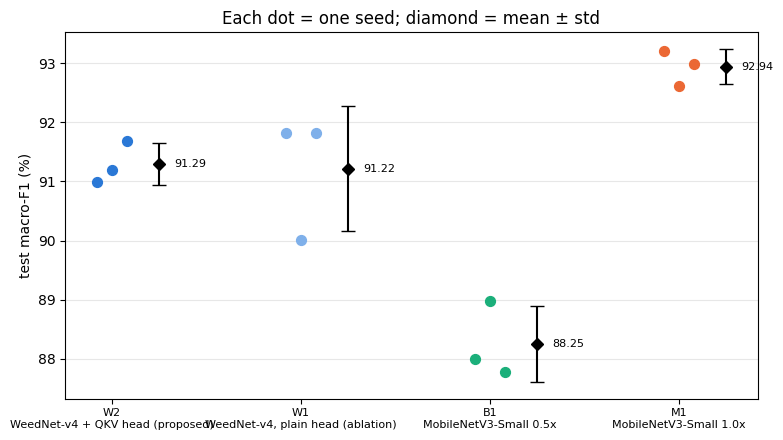

In [22]:
if not TIME_STATUS["out_of_time"]:
    ALL_LABELS = np.arange(num_classes)

    def macro_f1(yt, yp):
        return f1_score(yt, yp, average="macro", labels=ALL_LABELS, zero_division=0)

    def mcnemar_exact(y_true, pred_a, pred_b):
        a_ok, b_ok = pred_a == y_true, pred_b == y_true
        b, c = int(np.sum(a_ok & ~b_ok)), int(np.sum(~a_ok & b_ok))
        return b, c, (binomtest(min(b, c), b + c, 0.5).pvalue if b + c > 0 else 1.0)

    def holm(pvals):
        order = np.argsort(pvals)
        adj, running = np.empty(len(pvals)), 0.0
        for rank, k in enumerate(order):
            running = max(running, min(1.0, (len(pvals) - rank) * pvals[k]))
            adj[k] = running
        return adj

    def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=0):
        rng = np.random.default_rng(seed)
        n = len(y_true)
        stats = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
        return np.percentile(stats, [2.5, 97.5])

    def model_row(fam, s):
        mid = seed_id(fam, s)
        p, meta = PREDICTIONS[mid], EXPERIMENTS[mid]
        yt, yp = p["y_true"], p["y_pred"]
        h = meta["history"]
        kept = int(np.argmax(h["val_acc"]))
        return dict(id=fam, seed=s, model=FAMILIES[fam][0], macro_f1=macro_f1(yt, yp) * 100,
                    accuracy=accuracy_score(yt, yp) * 100,
                    rare_recall=recall_score(yt, yp, labels=rare_idx_list, average="macro", zero_division=0) * 100,
                    tail_recall=recall_score(yt, yp, labels=tail_idx_list, average="macro", zero_division=0) * 100,
                    clean_macro_f1=macro_f1(yt[TEST_CLEAN_MASK], yp[TEST_CLEAN_MASK]) * 100,
                    val_macro_f1=meta["val_f1_macro"] * 100,
                    train_val_gap=(h["train_acc"][kept] - h["val_acc"][kept]) * 100,
                    kept_epoch=kept + 1, epochs_run=len(h["val_acc"]), early_stopped=bool(meta.get("early_stopped")),
                    params_M=meta["total_params"] / 1e6, size_MB=meta["size_mb"], gmacs=meta["gmacs"],
                    train_h=meta["train_time_s"] / 3600)

    SEED_FAMS = [f for f in [PROPOSED] + SEED_REFS if any(seed_id(f, s) in PREDICTIONS for s in SEEDS)]
    seed_df = pd.DataFrame([model_row(f, s) for f in SEED_FAMS for s in SEEDS if seed_id(f, s) in PREDICTIONS])
    seed_df.to_csv(os.path.join(OUT_DIR, "seed_results.csv"), index=False)
    print("PER SEED (%)\n")
    print(seed_df.drop(columns=["model", "params_M", "size_MB", "gmacs"]).round(2).to_string(index=False))

    seed_metrics = ["macro_f1", "accuracy", "rare_recall", "clean_macro_f1", "train_val_gap"]
    seed_summary = seed_df.groupby("id", sort=False)[seed_metrics].agg(["mean", "std"]).round(2)
    SEED_COUNTS = seed_df.groupby("id", sort=False).size()
    seed_summary.to_csv(os.path.join(OUT_DIR, "seed_summary.csv"))
    print("\nMEAN ± STD OVER SEEDS (%)\n")
    for fam in SEED_FAMS:
        r = seed_summary.loc[fam]
        print(f"  {fam} {FAMILIES[fam][0]:<34} macro-F1 {r[('macro_f1', 'mean')]:.2f} ± {r[('macro_f1', 'std')]:.2f}   "
              f"accuracy {r[('accuracy', 'mean')]:.2f} ± {r[('accuracy', 'std')]:.2f}   "
              f"rare recall {r[('rare_recall', 'mean')]:.2f} ± {r[('rare_recall', 'std')]:.2f}   "
              f"gap {r[('train_val_gap', 'mean')]:.2f}   (n = {SEED_COUNTS[fam]} seeds)")

    print("\nPAIRED COMPARISONS (same seed, same test images)\n")
    PAIRED = {}
    for b_ in [f for f in SEED_REFS if f in SEED_FAMS]:
        diffs, wins, ps, used = [], 0, [], []
        for s in SEEDS:
            ia, ib = seed_id(PROPOSED, s), seed_id(b_, s)
            if ia in PREDICTIONS and ib in PREDICTIONS:
                yt = PREDICTIONS[ia]["y_true"]
                d = (macro_f1(yt, PREDICTIONS[ia]["y_pred"]) - macro_f1(yt, PREDICTIONS[ib]["y_pred"])) * 100
                p = mcnemar_exact(yt, PREDICTIONS[ia]["y_pred"], PREDICTIONS[ib]["y_pred"])[2]
                diffs.append(d); ps.append(p); wins += d > 0; used.append(s)
        if diffs:
            PAIRED[b_] = dict(diffs=diffs, ps=ps, wins=wins, seeds=used)
            sd = np.std(diffs, ddof=1) if len(diffs) > 1 else 0.0
            print(f"  {PROPOSED} − {b_}: {np.mean(diffs):+.2f} ± {sd:.2f} pp macro-F1 | {PROPOSED} better in "
                  f"{wins}/{len(diffs)} seeds | per seed {', '.join(f'{x:+.2f}' for x in diffs)} | McNemar p "
                  + ", ".join(f"{p:.4f}" for p in ps))
    pd.DataFrame([dict(pair=f"{PROPOSED}-{b_}", seed=s, delta_f1=d, p=p) for b_, v in PAIRED.items()
                  for s, d, p in zip(v["seeds"], v["diffs"], v["ps"])]).to_csv(
        os.path.join(OUT_DIR, "seed_pairs.csv"), index=False)

    SEED_COLORS = {"W2": "#2a78d6", "W1": "#7fb0ea", "M1": "#eb6834", "B1": "#1baf7a"}
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for k, fam in enumerate(SEED_FAMS):
        vals = seed_df.loc[seed_df["id"] == fam, "macro_f1"].values
        ax.scatter(np.full(len(vals), k) + np.linspace(-0.08, 0.08, len(vals)), vals, s=50, zorder=3,
                   color=SEED_COLORS.get(fam, "grey"))
        ax.errorbar(k + 0.25, vals.mean(), yerr=vals.std(ddof=1) if len(vals) > 1 else 0, fmt="D", color="black",
                    capsize=5, zorder=3)
        ax.text(k + 0.33, vals.mean(), f"{vals.mean():.2f}", va="center", fontsize=8)
    ax.set_xticks(range(len(SEED_FAMS)))
    ax.set_xticklabels([f"{f}\n{FAMILIES[f][0]}" for f in SEED_FAMS], fontsize=8)
    ax.set_ylabel("test macro-F1 (%)"); ax.grid(axis="y", alpha=0.3)
    ax.set_title("Each dot = one seed; diamond = mean ± std")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "seed_results.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

## 17. W2 Against Popular Models of Similar Size (Seed 42)

W2 (seed 42) against W1, MobileNetV3-Small 0.5× (B1), ShuffleNetV2 0.5× (S1), PP-LCNet 0.5× (L1), SqueezeNet 1.1 (Q1)
and MobileNetV3-Small (M1), on the same test images. Macro-F1 with a 95 % bootstrap CI (1,000 resamples), rare/tail
recall, macro-F1 on the duplicate-free test images (Section 5b), and the train–val gap. McNemar's exact test of W2
against each model, **Holm-adjusted** over all comparisons; a difference is called significant only when the
adjusted p < 0.05. Also: the per-class F1 heatmap of all models.

SEED 42 (%; CI = 95 % bootstrap interval of macro-F1), sorted by macro-F1

    macro_f1  ci_low  ci_high  accuracy  rare_recall  tail_recall  clean_macro_f1  train_val_gap  kept_epoch  params_M  size_MB  gmacs
id                                                                                                                                    
M1    93.214  92.064   94.151    92.269       94.202       96.865          93.036          3.211          26     1.545    6.021  0.056
L1    92.631  91.455   93.641    91.369       93.238       96.694          92.427          4.292          31     0.633    2.496  0.043
W1    91.824  90.523   92.969    90.903       92.761       96.485          91.695          1.878          43     0.513    2.073  0.044
W2    90.985  89.379   92.244    90.500       91.388       93.615          90.809          3.132          40     0.542    2.186  0.049
S1    89.539  87.874   90.848    88.979       90.849       92.612          89.302          1.776          34     0.

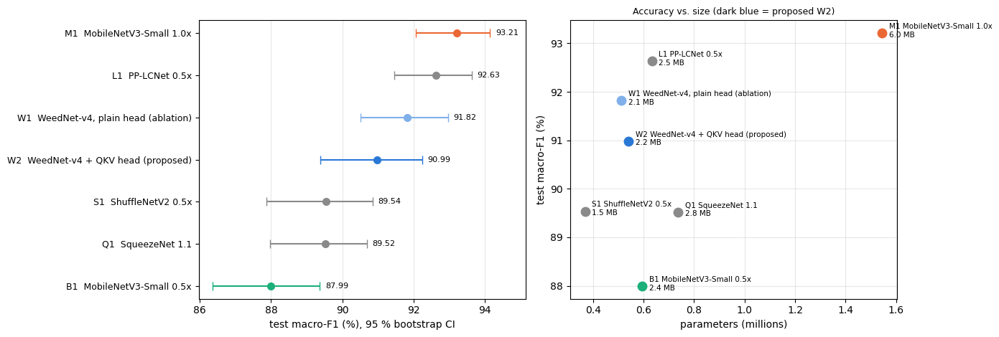

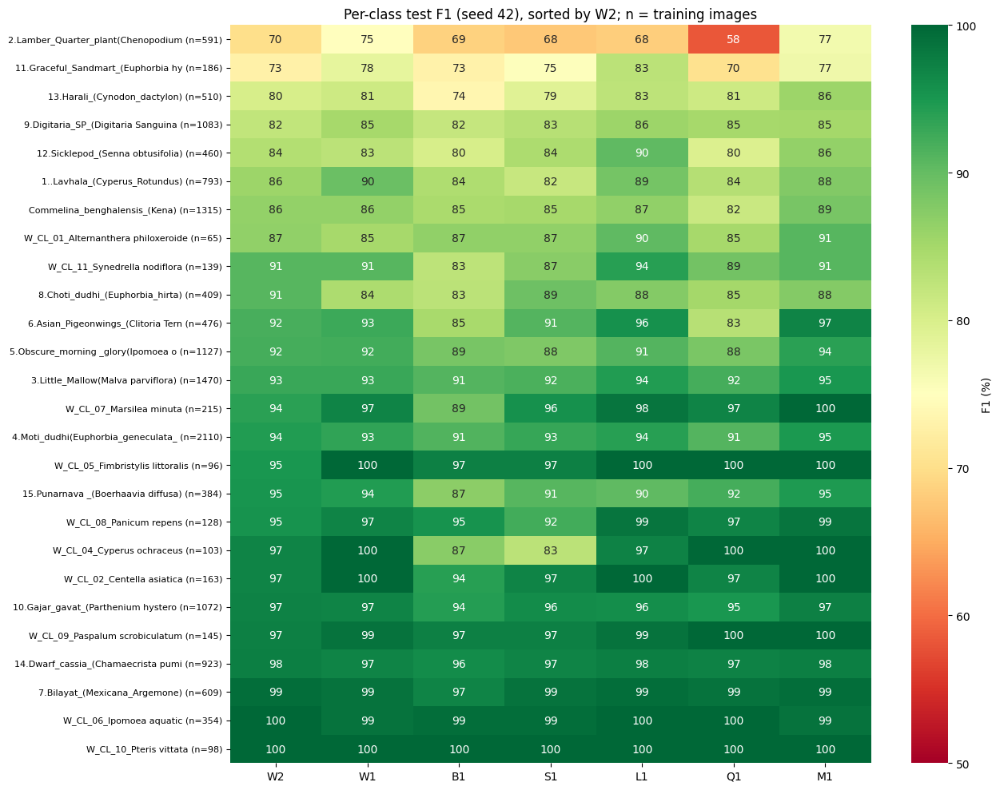

In [23]:
if not TIME_STATUS["out_of_time"]:
    CMP = [f for f in [PROPOSED, "W1"] + SAME_SIZE if seed_id(f, TRAIN_SEED) in PREDICTIONS]
    rows = []
    for fam in CMP:
        r = model_row(fam, TRAIN_SEED)
        p = PREDICTIONS[seed_id(fam, TRAIN_SEED)]
        r["ci_low"], r["ci_high"] = bootstrap_ci(p["y_true"], p["y_pred"]) * 100
        rows.append(r)
    cmp_df = pd.DataFrame(rows).set_index("id").sort_values("macro_f1", ascending=False)
    cmp_df.to_csv(os.path.join(OUT_DIR, "same_size_results.csv"))
    show = ["macro_f1", "ci_low", "ci_high", "accuracy", "rare_recall", "tail_recall", "clean_macro_f1",
            "train_val_gap", "kept_epoch", "params_M", "size_MB", "gmacs"]
    print("SEED 42 (%; CI = 95 % bootstrap interval of macro-F1), sorted by macro-F1\n")
    print(cmp_df[show].round(3).to_string())

    pair_rows = []
    a = seed_id(PROPOSED, TRAIN_SEED)
    for fam in [f for f in CMP if f != PROPOSED]:
        b = seed_id(fam, TRAIN_SEED)
        yt = PREDICTIONS[a]["y_true"]
        bb, cc, pv = mcnemar_exact(yt, PREDICTIONS[a]["y_pred"], PREDICTIONS[b]["y_pred"])
        pair_rows.append(dict(other=fam, other_model=FAMILIES[fam][0],
                              size_vs_W2=EXPERIMENTS[b]["total_params"] / EXPERIMENTS[a]["total_params"],
                              delta_f1=(macro_f1(yt, PREDICTIONS[a]["y_pred"]) - macro_f1(yt, PREDICTIONS[b]["y_pred"])) * 100,
                              only_W2_right=bb, only_other_right=cc, p=pv))
    vs_df = pd.DataFrame(pair_rows)
    if len(vs_df):
        vs_df["p_holm"] = holm(vs_df["p"].values)
        vs_df["significant"] = vs_df["p_holm"] < 0.05
        vs_df.to_csv(os.path.join(OUT_DIR, "vs_W2.csv"), index=False)
        print(f"\n{PROPOSED} − OTHER MODEL (macro-F1 pp; McNemar, Holm-adjusted over {len(vs_df)} comparisons)\n")
        print(vs_df.round(4).to_string(index=False))

    colors = {f: ("#2a78d6" if f == PROPOSED else "#7fb0ea" if f == "W1" else "#eb6834" if f == "M1"
                  else "#1baf7a" if f == "B1" else "#8a8a8a") for f in CMP}
    order = list(cmp_df.index)[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    ax = axes[0]
    for y, f in enumerate(order):
        r = cmp_df.loc[f]
        ax.errorbar(r.macro_f1, y, xerr=[[r.macro_f1 - r.ci_low], [r.ci_high - r.macro_f1]], fmt="o",
                    color=colors[f], capsize=4, ms=7)
        ax.text(r.ci_high + 0.15, y, f"{r.macro_f1:.2f}", va="center", fontsize=8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{f}  {FAMILIES[f][0]}" for f in order], fontsize=9)
    ax.set_xlim(right=cmp_df.ci_high.max() + 1.0)
    ax.set_xlabel("test macro-F1 (%), 95 % bootstrap CI"); ax.grid(axis="x", alpha=0.3)
    ax = axes[1]
    for f in CMP:
        r = cmp_df.loc[f]
        ax.plot(r.params_M, r.macro_f1, "o", color=colors[f], ms=9)
        ax.annotate(f"{f} {FAMILIES[f][0]}\n{r.size_MB:.1f} MB", (r.params_M, r.macro_f1), textcoords="offset points",
                    xytext=(7, -4), fontsize=7.5)
    ax.set_xlabel("parameters (millions)"); ax.set_ylabel("test macro-F1 (%)"); ax.grid(alpha=0.3)
    ax.set_title("Accuracy vs. size (dark blue = proposed W2)", fontsize=9)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "same_size.png"), dpi=150); plt.show()

    pc = pd.DataFrame({f: precision_recall_fscore_support(PREDICTIONS[seed_id(f, TRAIN_SEED)]["y_true"],
                                                          PREDICTIONS[seed_id(f, TRAIN_SEED)]["y_pred"],
                                                          labels=ALL_LABELS, zero_division=0)[2] * 100
                       for f in CMP}, index=class_names)
    pc["n_train"] = train_class_n.astype(int)
    pc = pc.sort_values(PROPOSED)
    pc.to_csv(os.path.join(OUT_DIR, "per_class_f1.csv"))
    fig, ax = plt.subplots(figsize=(1.3 * len(CMP) + 4, 10))
    sns.heatmap(pc.drop(columns="n_train"), annot=True, fmt=".0f", cmap="RdYlGn", vmin=50, vmax=100,
                cbar_kws={"label": "F1 (%)"}, ax=ax)
    ax.set_yticklabels([f"{c[:34]} (n={n})" for c, n in zip(pc.index, pc["n_train"])], fontsize=8)
    ax.set_title(f"Per-class test F1 (seed 42), sorted by {PROPOSED}; n = training images")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "per_class_f1.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

## 18. Overfitting Check

For every model (seed 42): training vs validation accuracy at the kept checkpoint, the largest gap during
training, how much the validation loss rose after its minimum, and validation vs test macro-F1. Training accuracy is
logged on augmented, re-sampled batches with dropout active, so the gaps are indicative.

OVERFITTING CHECK (seed 42, %)

                                model  epochs  early_stopped  kept_epoch  train_acc  val_acc   gap  max_gap  val_loss_rise_pct  val_f1  test_f1  val_minus_test_f1
id                                                                                                                                                                
W2   WeedNet-v4 + QKV head (proposed)      50          False          40      93.84    90.71  3.13     3.67               1.76   91.11    90.99               0.13
W1  WeedNet-v4, plain head (ablation)      50          False          43      93.40    91.52  1.88     2.80               3.25   92.16    91.82               0.33
B1             MobileNetV3-Small 0.5x      50          False          43      93.29    89.10  4.19     6.04               2.76   89.69    87.99               1.69
M1             MobileNetV3-Small 1.0x      36           True          26      96.53    93.32  3.21     4.63               2.24   94.11    93.21          

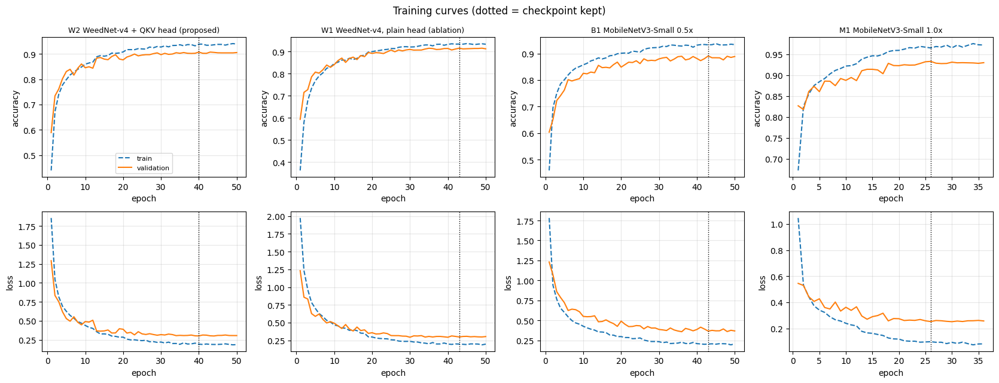

In [24]:
if not TIME_STATUS["out_of_time"]:
    of_rows = []
    OF_IDS = [f for f in [PROPOSED, "W1", "B1", "M1", "S1", "L1", "Q1"] if f in EXPERIMENTS]
    for f in OF_IDS:
        meta, p = EXPERIMENTS[f], PREDICTIONS[f]
        h = meta["history"]
        ta, va, vl = np.array(h["train_acc"]), np.array(h["val_acc"]), np.array(h["val_loss"])
        k, lmin = int(np.argmax(va)), int(np.argmin(vl))
        of_rows.append(dict(id=f, model=FAMILIES[f][0], epochs=len(va), early_stopped=bool(meta.get("early_stopped")),
                            kept_epoch=k + 1, train_acc=ta[k] * 100, val_acc=va[k] * 100, gap=(ta[k] - va[k]) * 100,
                            max_gap=(ta - va).max() * 100, val_loss_rise_pct=(vl[-1] - vl[lmin]) / vl[lmin] * 100,
                            val_f1=meta["val_f1_macro"] * 100, test_f1=macro_f1(p["y_true"], p["y_pred"]) * 100))
    of_df = pd.DataFrame(of_rows).set_index("id")
    of_df["val_minus_test_f1"] = of_df["val_f1"] - of_df["test_f1"]
    of_df.to_csv(os.path.join(OUT_DIR, "overfitting.csv"))
    print("OVERFITTING CHECK (seed 42, %)\n")
    print(of_df.round(2).to_string())

    curve_ids = [f for f in [PROPOSED, "W1", "B1", "M1"] if f in EXPERIMENTS]
    fig, axes = plt.subplots(2, len(curve_ids), figsize=(4.2 * len(curve_ids), 6.5), squeeze=False)
    for j, f in enumerate(curve_ids):
        h = EXPERIMENTS[f]["history"]
        ep = np.arange(1, len(h["val_acc"]) + 1)
        k = int(np.argmax(h["val_acc"])) + 1
        for r, (a, b, lab) in enumerate((("train_acc", "val_acc", "accuracy"), ("train_loss", "val_loss", "loss"))):
            ax = axes[r, j]
            ax.plot(ep, h[a], "--", label="train"); ax.plot(ep, h[b], "-", label="validation")
            ax.axvline(k, color="black", ls=":", lw=1); ax.set_xlabel("epoch"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
            if r == 0:
                ax.set_title(f"{f} {FAMILIES[f][0]}", fontsize=9)
    axes[0, 0].legend(fontsize=8)
    plt.suptitle("Training curves (dotted = checkpoint kept)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "overfitting_curves.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

## 19. Per-Class Results and Confusion Matrix of W2

Per-class precision, recall and F1 of W2 (seed 42), sorted from the weakest class, and its row-normalised confusion
matrix (cells ≥ 0.05 labelled). Classes of Dataset 1 (`W_CL_*`) are separated from those of Dataset 2 by lines;
errors that cross the line would mean the model confused the two datasets.

                                           cls  train_images  test_images  precision  recall    f1
          2.Lamber_Quarter_plant(Chenopodium )           591          130       77.6    63.8  70.0
11.Graceful_Sandmart_(Euphorbia hypericifolia)           186           37       62.7    86.5  72.7
                  13.Harali_(Cynodon_dactylon)           510          107       75.8    85.0  80.2
       9.Digitaria_SP_(Digitaria Sanguinalis )          1083          235       82.5    82.1  82.3
              12.Sicklepod_(Senna obtusifolia)           460          108       84.1    83.3  83.7
                 1..Lavhala_(Cyperus_Rotundus)           793          191       85.8    85.3  85.6
                 Commelina_benghalensis_(Kena)          1315          300       86.9    86.0  86.4
            W_CL_01_Alternanthera philoxeroide            65           17      100.0    76.5  86.7
                  W_CL_11_Synedrella nodiflora           139           25       83.3   100.0  90.9
          

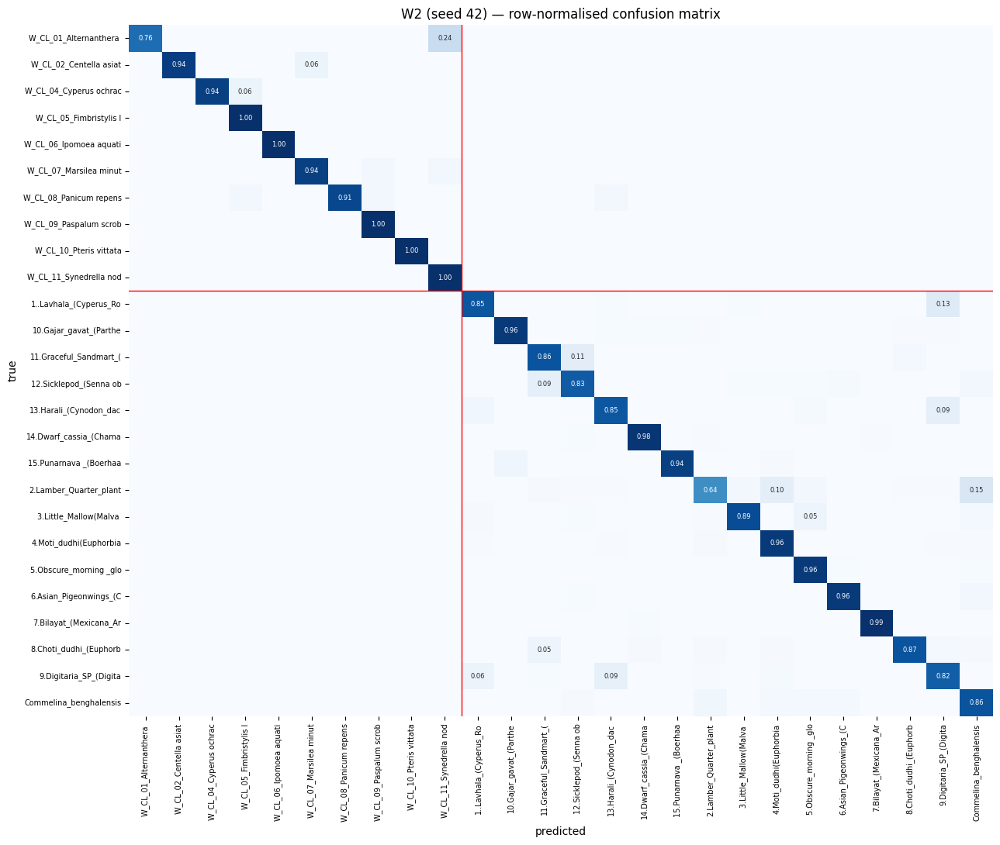

In [25]:
if not TIME_STATUS["out_of_time"]:
    p = PREDICTIONS[PROPOSED]
    prec, rec, f1c, sup = precision_recall_fscore_support(p["y_true"], p["y_pred"], labels=ALL_LABELS, zero_division=0)
    w2_pc = pd.DataFrame(dict(cls=class_names, train_images=train_class_n.astype(int), test_images=sup,
                              precision=prec * 100, recall=rec * 100, f1=f1c * 100)).sort_values("f1")
    w2_pc.to_csv(os.path.join(OUT_DIR, "w2_per_class.csv"), index=False)
    print(w2_pc.round(1).to_string(index=False))

    order = [i for i, c in enumerate(class_names) if c.startswith("W_CL")] + \
            [i for i, c in enumerate(class_names) if not c.startswith("W_CL")]
    n_d1 = sum(c.startswith("W_CL") for c in class_names)
    cm = confusion_matrix(p["y_true"], p["y_pred"], labels=order, normalize="true")
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(cm, cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=False, xticklabels=[class_names[i][:22] for i in order],
                yticklabels=[class_names[i][:22] for i in order],
                annot=np.where(cm >= 0.05, np.char.mod("%.2f", cm), ""), fmt="", annot_kws={"fontsize": 6})
    ax.axhline(n_d1, color="red", lw=1); ax.axvline(n_d1, color="red", lw=1)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.tick_params(labelsize=7)
    ax.set_title(f"{PROPOSED} (seed 42) — row-normalised confusion matrix")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "w2_confusion_matrix.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

## 20. Source Test — Results

For each source dataset, the same test images are scored three ways:

| Row | Meaning |
|---|---|
| **26-class W1** | W1 as it is (seed 42); may wrongly predict a class from the other dataset |
| **26-class W1, source given** | the same model, but its prediction is restricted to that dataset's classes (as if told the source) |
| **single-source W1** | W1 trained only on this dataset, so it cannot use the source as a shortcut |

**How to read it:**
- **single-source ≈ 26-class (within ~2 pp)** — the 26-class model's recognition *within* a dataset is genuine;
  telling the two datasets apart is the only extra step it takes. The ~0 % cross-source errors are then harmless:
  the species of the two datasets are separable, whether by plant or by photo style.
- **single-source clearly lower** — most likely **less training data**. A single-source model sees only its own
  dataset (Dataset 1: ~1,600 training images), while the 26-class model also learns useful features from the
  other dataset. This alone is **not** evidence of a shortcut.
- **single-source clearly higher** — the other dataset's classes were confusing the 26-class model.

**What this test can and cannot show.** The 26-class task splits into two steps: (a) telling the two datasets
apart, and (b) recognising the species within a dataset. The single-source models measure step (b) cleanly,
with no source cue available. That covers the real recognition work: 11 and 16 visually similar weeds taken
with the same camera. The test **cannot** show *how* the 26-class model does step (a), by plant or by photo
style. That only matters for photos from a new camera or field, and can only be checked with such photos.
State it as a limitation.

Dataset 1 has only 343 test images (17–37 per class), so its per-class numbers can move by several points from
one or two images.

SOURCE TEST (%)

                             source                   scoring  test_images  macro_f1  accuracy  predicted_other_dataset_pct
          Dataset 1 (Rice Field BD)               26-class W1          343     96.97     97.38                         0.29
          Dataset 1 (Rice Field BD) 26-class W1, source given          343     97.12     97.67                         0.00
          Dataset 1 (Rice Field BD)          single-source W1          343     89.72     91.84                         0.00
Dataset 2 (Individual Weed Species)               26-class W1         2878     88.72     90.13                         0.03
Dataset 2 (Individual Weed Species) 26-class W1, source given         2878     88.76     90.17                         0.00
Dataset 2 (Individual Weed Species)          single-source W1         2878     88.21     89.92                         0.00

PER CLASS F1 (%): 26-class W1 vs single-source W1

source                                            cls  test_ima

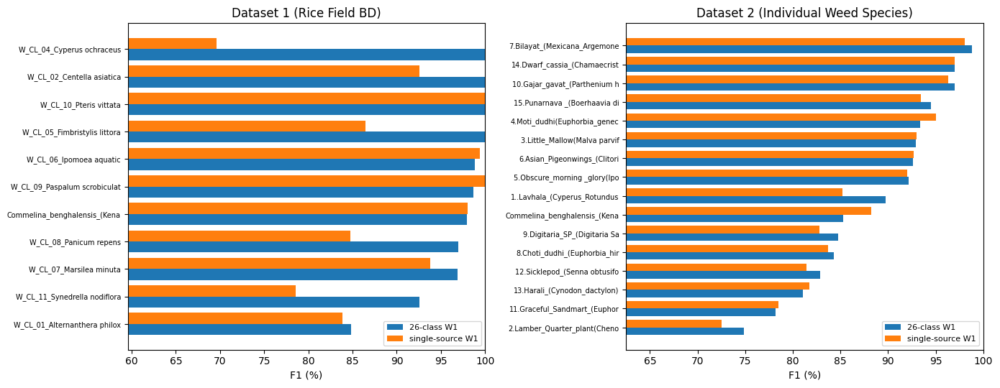

In [26]:
if not TIME_STATUS["out_of_time"]:
    if not SOURCE_RESULTS or "W1" not in PREDICTIONS:
        print("Source test or W1 (seed 42) not available — skipping")
    else:
        w1 = PREDICTIONS["W1"]
        test_src = np.array([sample_source(i) for i in test_indices])
        src_rows, per_class_rows = [], []
        for src, R in SOURCE_RESULTS.items():
            S = SOURCE_SPLITS[src]
            cls = np.array(S["classes"])
            m = test_src == src
            yt = w1["y_true"][m]
            pred_26 = w1["y_pred"][m]
            pred_given = cls[np.argmax(w1["y_prob"][m][:, cls], axis=1)]
            pred_single = cls[R["y_pred"]]
            assert np.array_equal(cls[R["y_true"]], yt), "test images differ between the runs"
            outside = np.mean(~np.isin(pred_26, cls)) * 100
            for name, yp in (("26-class W1", pred_26), ("26-class W1, source given", pred_given),
                             ("single-source W1", pred_single)):
                src_rows.append(dict(source=S["label"], scoring=name, test_images=int(m.sum()),
                                     macro_f1=f1_score(yt, yp, average="macro", labels=cls, zero_division=0) * 100,
                                     accuracy=accuracy_score(yt, yp) * 100,
                                     predicted_other_dataset_pct=outside if name == "26-class W1" else 0.0))
            f_26 = precision_recall_fscore_support(yt, pred_26, labels=cls, zero_division=0)[2]
            f_single = precision_recall_fscore_support(yt, pred_single, labels=cls, zero_division=0)[2]
            for c, a, b in zip(cls, f_26, f_single):
                per_class_rows.append(dict(source=src, cls=class_names[c], test_images=int(np.sum(yt == c)),
                                           f1_26_class=a * 100, f1_single_source=b * 100, diff_pp=(b - a) * 100))
        src_df = pd.DataFrame(src_rows)
        pc_df = pd.DataFrame(per_class_rows).sort_values(["source", "diff_pp"])
        src_df.to_csv(os.path.join(OUT_DIR, "source_test.csv"), index=False)
        pc_df.to_csv(os.path.join(OUT_DIR, "source_test_per_class.csv"), index=False)
        print("SOURCE TEST (%)\n")
        print(src_df.round(2).to_string(index=False))
        print("\nPER CLASS F1 (%): 26-class W1 vs single-source W1\n")
        print(pc_df.round(1).to_string(index=False))

        fig, axes = plt.subplots(1, len(SOURCE_RESULTS), figsize=(7 * len(SOURCE_RESULTS), 5.5), squeeze=False)
        for ax, (src, g) in zip(axes[0], pc_df.groupby("source")):
            g = g.sort_values("f1_26_class")
            y = np.arange(len(g))
            ax.barh(y - 0.2, g["f1_26_class"], 0.4, label="26-class W1")
            ax.barh(y + 0.2, g["f1_single_source"], 0.4, label="single-source W1")
            ax.set_yticks(y); ax.set_yticklabels([n[:28] for n in g["cls"]], fontsize=7)
            ax.set_xlim(max(0, min(g["f1_26_class"].min(), g["f1_single_source"].min()) - 10), 100)
            ax.set_xlabel("F1 (%)"); ax.set_title(SOURCE_SPLITS[src]["label"]); ax.legend(fontsize=8)
        plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "source_test.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

---
# Part 3 — Explanation Maps

## 21. Attention Maps of W2

For every image, the attention head records how much the `[CLS]` token attended to each of the 7×7 positions
(averaged over the 4 heads). Upsampled to the image, this is an **explanation map that comes with every
prediction**, with no extra method. The plain head (W1) cannot provide this: it averages all
positions with equal weight.

The cell shows:
1. **Maps for 8 correct and 8 wrong test predictions** of W2 (seed 42, fixed random choice). Good evidence for the
   thesis: does the model look at the plant, or at soil, background, edges?
2. **How concentrated the attention is** over the whole test set: the share of attention on the top 5 of 49
   positions (uniform attention = 10 %), and the entropy relative to uniform attention (1.0 = looks everywhere
   equally). Reported for correct and wrong predictions separately.

Section 22 tests whether these maps reflect what the model really uses.

ATTENTION CONCENTRATION ([CLS] -> 49 positions; uniform = 10.2 % on the top 5, entropy 1.0)

predictions  images  top5_share_%  relative_entropy
        all    3221     36.566002             0.858
    correct    2915     36.431000             0.859
      wrong     306     37.858002             0.857


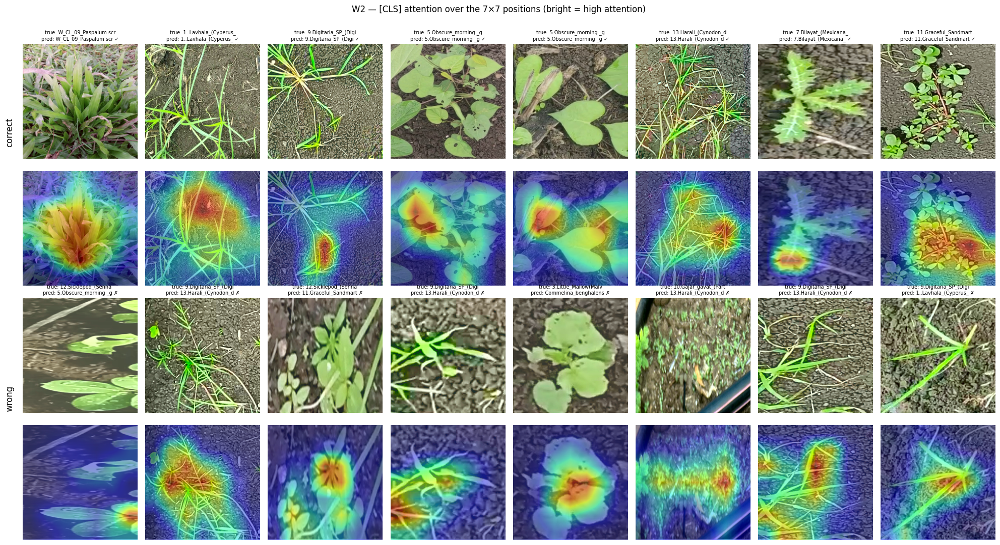

In [27]:
if not TIME_STATUS["out_of_time"]:
    w2_id = seed_id(PROPOSED, TRAIN_SEED)
    if w2_id not in PREDICTIONS:
        print("W2 (seed 42) not available — skipping")
    else:
        attn_model = FAMILIES[PROPOSED][2]().to(device)
        attn_model.load_state_dict(torch.load(os.path.join(OUT_DIR, f"{w2_id}.pt"), map_location=device))
        attn_model.eval()

        # ---- 1. attention concentration over the whole test set ----
        top5_share, rel_entropy = [], []
        with torch.no_grad():
            for inputs, _ in merged_test_loader:
                attn_model(inputs.to(device))
                a = attn_model.head.last_attn[:, :, 0, 1:].mean(1)        # (B, 49): [CLS] -> positions, mean of heads
                a = a / a.sum(1, keepdim=True)
                top5_share.append(a.topk(5, dim=1).values.sum(1).cpu().numpy())
                rel_entropy.append((-(a * (a + 1e-12).log()).sum(1) / np.log(a.shape[1])).cpu().numpy())
        top5_share, rel_entropy = np.concatenate(top5_share), np.concatenate(rel_entropy)
        ok = PREDICTIONS[w2_id]["y_pred"] == PREDICTIONS[w2_id]["y_true"]
        conc = pd.DataFrame({"predictions": ["all", "correct", "wrong"],
                             "images": [len(ok), ok.sum(), (~ok).sum()],
                             "top5_share_%": [top5_share.mean() * 100, top5_share[ok].mean() * 100,
                                              top5_share[~ok].mean() * 100],
                             "relative_entropy": [rel_entropy.mean(), rel_entropy[ok].mean(), rel_entropy[~ok].mean()]})
        conc.to_csv(os.path.join(OUT_DIR, "attention_concentration.csv"), index=False)
        print("ATTENTION CONCENTRATION ([CLS] -> 49 positions; uniform = 10.2 % on the top 5, entropy 1.0)\n")
        print(conc.round(3).to_string(index=False))

        # ---- 2. maps for correct and wrong predictions ----
        rs = np.random.RandomState(0)
        pick = [(0, j, i) for j, i in enumerate(rs.choice(np.where(ok)[0], min(8, int(ok.sum())), replace=False))] +                [(2, j, i) for j, i in enumerate(rs.choice(np.where(~ok)[0], min(8, int((~ok).sum())), replace=False))]
        eval_tf = get_eval_transform(IMG_SIZE)
        fig, axes = plt.subplots(4, 8, figsize=(20, 11))
        for row, col, i in pick:
            img, label = test_subset[i]
            with torch.no_grad():
                pred = attn_model(eval_tf(img).unsqueeze(0).to(device)).argmax(1).item()
            cls_attn = attn_model.head.last_attn[0, :, 0, 1:].mean(0)
            side = int(round(cls_attn.numel() ** 0.5))
            amap = cls_attn.reshape(side, side).cpu().numpy()
            shown = harmonize(img).resize((IMG_SIZE, IMG_SIZE))
            axes[row, col].imshow(shown)
            axes[row, col].set_title(f"true: {class_names[label][:20]}\npred: {class_names[pred][:20]} "
                                     f"{'✓' if pred == label else '✗'}", fontsize=7)
            axes[row + 1, col].imshow(shown)
            axes[row + 1, col].imshow(amap, cmap="jet", alpha=0.45, extent=(0, IMG_SIZE, IMG_SIZE, 0),
                                      interpolation="bilinear")
        for ax in axes.ravel():
            ax.axis("off")
        fig.text(0.01, 0.75, "correct", rotation=90, fontsize=12, va="center")
        fig.text(0.01, 0.27, "wrong", rotation=90, fontsize=12, va="center")
        plt.suptitle("W2 — [CLS] attention over the 7×7 positions (bright = high attention)")
        plt.tight_layout(rect=(0.02, 0, 1, 0.97))
        plt.savefig(os.path.join(OUT_DIR, "attention_maps.png"), dpi=150); plt.show()
        del attn_model
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

## 22. Faithfulness of the Attention Map

A map can look plausible (it lies on the plant) without reflecting the model's decision. Two standard tests:

1. **Deletion / insertion** (Petsiuk et al., 2018). The image is divided into the 7×7 = 49 cells of the map.
   *Deletion:* cells are replaced one by one by a blurred copy, most attended first; if the map is faithful, the
   probability of the predicted class falls **quickly** (area under the curve: lower = better). *Insertion:* start
   from the blurred image and restore the cells, most attended first (AUC: higher = better). Baseline: the same with
   a **random** cell order. `N_FAITH` test images.
2. **Model randomisation** (Adebayo et al., 2018). The learned weights are replaced by random ones step by step (head;
   + domain blocks; + stem). A faithful map must then change: its Spearman correlation with the trained model's map
   should fall towards 0. `N_SANITY` test images.

DELETION (lower = more faithful) / INSERTION (higher = more faithful), 500 test images, start probability 0.925

               map  deletion_auc  insertion_auc  beats_random_deletion_pct  beats_random_insertion_pct
QKV attention (W2)         0.220          0.533                       81.2                        89.8
      random order         0.336          0.336                        NaN                         NaN


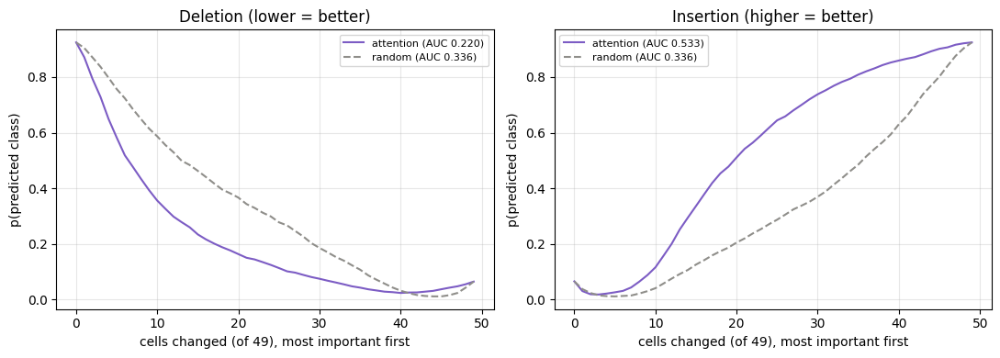


SANITY CHECK: Spearman of the attention maps with those of the trained model (0 = unrelated)

                 randomised  attention_spearman
                       head               0.084
       head + domain blocks               0.167
head + domain blocks + stem              -0.037


In [28]:
if not TIME_STATUS["out_of_time"]:
    from torchvision.transforms.functional import gaussian_blur


    def load_weednet(mid, attention_head):
        m = WeedNetV4(num_classes, attention_head=attention_head).to(device)
        m.load_state_dict(torch.load(os.path.join(OUT_DIR, f"{mid}.pt"), map_location=device))
        return m.eval()


    W2_MODEL = load_weednet(PROPOSED, True)
    eval_tf = get_eval_transform(IMG_SIZE)


    @torch.no_grad()
    def attention_maps(model, x):
        model(x)
        return model.head.last_attn[:, :, 0, 1:].mean(1).reshape(-1, 7, 7)


    def batch_from(indices):
        imgs, labels = zip(*(test_subset[i] for i in indices))
        return torch.stack([eval_tf(im) for im in imgs]).to(device), torch.tensor(labels, device=device), imgs


    CELL = IMG_SIZE // 7


    def cell_masks(order):
        masks = torch.zeros(50, 1, IMG_SIZE, IMG_SIZE, device=device)
        for k in range(1, 50):
            r, c = divmod(int(order[k - 1]), 7)
            masks[k:, :, r * CELL:(r + 1) * CELL, c * CELL:(c + 1) * CELL] = 1
        masks[49:, :] = 1
        return masks


    @torch.no_grad()
    def deletion_insertion(model, x1, saliency, cls):
        blurred = gaussian_blur(x1, kernel_size=51, sigma=20.0)
        m = cell_masks(saliency.flatten().argsort(descending=True))
        p_del = F.softmax(model(x1 * (1 - m) + blurred * m), 1)[:, cls].cpu().numpy()
        p_ins = F.softmax(model(blurred * (1 - m) + x1 * m), 1)[:, cls].cpu().numpy()
        return p_del, p_ins


    faith_idx = np.random.RandomState(2).choice(len(test_subset), N_FAITH, replace=False)
    curves = {k: {"del": [], "ins": []} for k in ("attention", "random")}
    g_rand = torch.Generator().manual_seed(0)
    for s in range(0, N_FAITH, 32):
        x, _, _ = batch_from(faith_idx[s:s + 32])
        with torch.no_grad():
            pred = W2_MODEL(x).argmax(1)
        att = attention_maps(W2_MODEL, x)
        rnd = torch.rand(len(x), 7, 7, generator=g_rand).to(device)
        for b in range(len(x)):
            for name, sal in (("attention", att[b]), ("random", rnd[b])):
                d_, i_ = deletion_insertion(W2_MODEL, x[b:b + 1], sal, int(pred[b]))
                curves[name]["del"].append(d_); curves[name]["ins"].append(i_)
    FAITH_CURVES = {k: {kind: np.array(v[kind]) for kind in v} for k, v in curves.items()}
    np.savez_compressed(os.path.join(OUT_DIR, "faithfulness_curves.npz"),
                        **{f"{k}_{kind}": v for k, d_ in FAITH_CURVES.items() for kind, v in d_.items()})
    att_del, att_ins = FAITH_CURVES["attention"]["del"].mean(1), FAITH_CURVES["attention"]["ins"].mean(1)
    rnd_del, rnd_ins = FAITH_CURVES["random"]["del"].mean(1), FAITH_CURVES["random"]["ins"].mean(1)
    faith_df = pd.DataFrame([
        dict(map="QKV attention (W2)", deletion_auc=att_del.mean(), insertion_auc=att_ins.mean(),
             beats_random_deletion_pct=(att_del < rnd_del).mean() * 100,
             beats_random_insertion_pct=(att_ins > rnd_ins).mean() * 100),
        dict(map="random order", deletion_auc=rnd_del.mean(), insertion_auc=rnd_ins.mean(),
             beats_random_deletion_pct=np.nan, beats_random_insertion_pct=np.nan)])
    faith_df.to_csv(os.path.join(OUT_DIR, "faithfulness.csv"), index=False)
    print(f"DELETION (lower = more faithful) / INSERTION (higher = more faithful), {N_FAITH} test images, "
          f"start probability {FAITH_CURVES['attention']['del'][:, 0].mean():.3f}\n")
    print(faith_df.round(3).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, kind, title in ((axes[0], "del", "Deletion (lower = better)"), (axes[1], "ins", "Insertion (higher = better)")):
        for name, color, ls in (("attention", "#7c5cc4", "-"), ("random", "#8f8e8a", "--")):
            m = FAITH_CURVES[name][kind].mean(0)
            ax.plot(np.arange(50), m, color=color, ls=ls, label=f"{name} (AUC {m.mean():.3f})")
        ax.set_xlabel("cells changed (of 49), most important first"); ax.set_ylabel("p(predicted class)")
        ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "faithfulness_curves.png"), dpi=150); plt.show()


    # ---- model-randomisation sanity check ----
    def randomise(model, parts):
        m = copy.deepcopy(model)
        for part in parts:
            for mod in getattr(m, part).modules():
                if isinstance(mod, (nn.Conv2d, nn.Linear)):
                    nn.init.normal_(mod.weight, 0, 0.05)
                    if mod.bias is not None:
                        nn.init.zeros_(mod.bias)
            if part == "head":
                nn.init.normal_(m.head.cls, 0, 0.02); nn.init.normal_(m.head.pos, 0, 0.02)
        return m.eval()


    x_s, _, _ = batch_from(np.random.RandomState(3).choice(len(test_subset), N_SANITY, replace=False))
    ref_att = attention_maps(W2_MODEL, x_s).cpu().numpy()
    san_rows = []
    for label, parts in (("head", ["head"]), ("head + domain blocks", ["head", "domain_blocks"]),
                         ("head + domain blocks + stem", ["head", "domain_blocks", "imagenet_stem"])):
        rm = randomise(W2_MODEL, parts)
        att_r = attention_maps(rm, x_s).cpu().numpy()
        rho = np.nanmean([spearmanr(a.ravel(), b.ravel()).correlation for a, b in zip(ref_att, att_r)])
        san_rows.append(dict(randomised=label, attention_spearman=rho))
        del rm
    sanity_df = pd.DataFrame(san_rows)
    sanity_df.to_csv(os.path.join(OUT_DIR, "sanity_check.csv"), index=False)
    print("\nSANITY CHECK: Spearman of the attention maps with those of the trained model (0 = unrelated)\n")
    print(sanity_df.round(3).to_string(index=False))
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

---
# Part 4 — Advisory Layer

A classifier always outputs a class, even for a blurred photo or a species it has never seen. A field tool should
instead say how sure it is, and give advice only when it is reliable. The advisory layer is built on top of the
unchanged W2 model, in three steps, all fitted on the **validation** set and evaluated on the **test** set.

## 23. Calibration: Does "95 % Confident" Mean 95 % Correct?

**Temperature scaling** (Guo et al., 2017): all logits are divided by one number *T*, chosen to minimise the
validation log-loss. It never changes the predicted class (so accuracy and macro-F1 stay identical), only the
confidence. Measured with the **expected calibration error (ECE**, 15 bins; 0 = perfectly calibrated) and a
reliability diagram. Done for all three W2 seeds.

TEMPERATURE SCALING (fitted on validation, evaluated on test; ECE in %)

 model  temperature  val_nll_before  val_nll_after  test_ece_before  test_ece_after  test_mean_conf_before  test_mean_conf_after  test_accuracy
    W2        1.140           0.301          0.296            2.522           1.141                 92.251                90.555         90.500
W2_s43        1.101           0.287          0.285            1.550           0.797                 91.919                90.689         90.717
W2_s44        1.181           0.261          0.254            2.868           1.327                 93.865                92.087         91.214


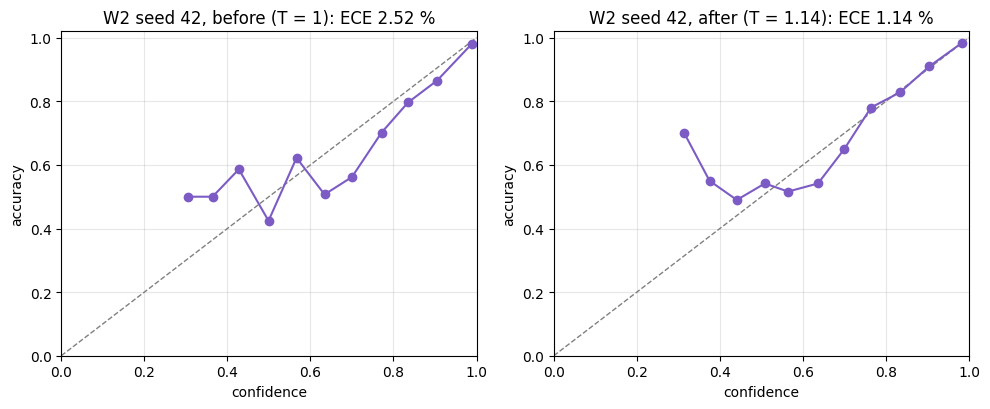

In [29]:
if not TIME_STATUS["out_of_time"]:
    @torch.no_grad()
    def log_probs(model, loader):
        out, ys = [], []
        for xb, yb in loader:
            out.append(F.log_softmax(model(xb.to(device)), 1).cpu()); ys.append(yb)
        return torch.cat(out).numpy().astype(np.float64), torch.cat(ys).numpy()


    def softmax_T(logp, T):
        z = logp / T
        z = z - z.max(1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(1, keepdims=True)


    def nll(logp, y, T):
        return -np.log(softmax_T(logp, T)[np.arange(len(y)), y] + 1e-12).mean()


    def ece(prob, y, bins=15):
        conf, pred = prob.max(1), prob.argmax(1)
        edges = np.linspace(0, 1, bins + 1)
        e = 0.0
        for lo, hi in zip(edges[:-1], edges[1:]):
            m = (conf > lo) & (conf <= hi)
            if m.any():
                e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
        return e


    CAL = {}
    cal_rows = []
    for s in SEEDS:
        mid = seed_id(PROPOSED, s)
        model = W2_MODEL if mid == "W2" else load_weednet(mid, True)
        lv, yv = log_probs(model, merged_val_loader)
        lt, yt = log_probs(model, merged_test_loader)
        grid = np.exp(np.linspace(np.log(0.3), np.log(10), 500))
        T = grid[np.argmin([nll(lv, yv, t) for t in grid])]
        CAL[mid] = dict(T=T, val=(lv, yv), test=(lt, yt))
        pt0, pt1 = softmax_T(lt, 1.0), softmax_T(lt, T)
        cal_rows.append(dict(model=mid, temperature=T, val_nll_before=nll(lv, yv, 1.0), val_nll_after=nll(lv, yv, T),
                             test_ece_before=ece(pt0, yt) * 100, test_ece_after=ece(pt1, yt) * 100,
                             test_mean_conf_before=pt0.max(1).mean() * 100, test_mean_conf_after=pt1.max(1).mean() * 100,
                             test_accuracy=(pt1.argmax(1) == yt).mean() * 100))
        if model is not W2_MODEL:
            del model
    cal_df = pd.DataFrame(cal_rows)
    cal_df.to_csv(os.path.join(OUT_DIR, "calibration.csv"), index=False)
    print("TEMPERATURE SCALING (fitted on validation, evaluated on test; ECE in %)\n")
    print(cal_df.round(3).to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    lt, yt = CAL["W2"]["test"]
    for ax, T, title in ((axes[0], 1.0, "before (T = 1)"), (axes[1], CAL["W2"]["T"], f"after (T = {CAL['W2']['T']:.2f})")):
        p = softmax_T(lt, T)
        conf, ok = p.max(1), p.argmax(1) == yt
        edges = np.linspace(0, 1, 16)
        mids, accs, counts = [], [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            m = (conf > lo) & (conf <= hi)
            if m.sum() >= 5:
                mids.append(conf[m].mean()); accs.append(ok[m].mean()); counts.append(m.sum())
        ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
        ax.plot(mids, accs, "o-", color="#7c5cc4")
        ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_title(f"W2 seed 42, {title}: ECE {ece(p, yt) * 100:.2f} %")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "reliability.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

## 24. Three-Level Decision: Species, Weed Group, or "Not Sure"

Most control decisions depend on the **weed group** (grass, sedge, broadleaf, fern), not only on the exact species,
and the model's errors are mostly confusions *within* a group (e.g. *Digitaria* ↔ *Cynodon*, both grasses). The
layer therefore answers at the most specific level it is reliable at:

1. **Species** — if the calibrated top probability ≥ τ_species.
2. **Weed group** — otherwise, if the summed probability of all classes in the top class's group ≥ τ_group.
   Example: "a grass weed (most likely *Cynodon dactylon* or *Digitaria sanguinalis*)".
3. **Not sure** — otherwise: "retake the photo closer, in daylight, or show it to an extension officer".

τ_species and τ_group are chosen on the **validation** set as the lowest thresholds at which the answers given were
at least `TARGET_ACC` (98 %) correct. The test set then shows the real coverage and accuracy. A
**risk–coverage curve** shows the whole trade-off between answering more often and being right more often.

`SPECIES_INFO` gives each class its scientific name, group and life cycle. Folder names contain typos; the keys
below are matched to them.

broadleaf    17
grass         4
sedge         3
fern          2

ADVISORY LAYER ON THE TEST SET (thresholds from validation, target accuracy 98%)

 model    T  tau_species  tau_group  species_answers_pct  species_accuracy  group_answers_pct  group_accuracy  not_sure_pct  accuracy_if_forced_on_not_sure  plain_accuracy  advice_correct_pct  wrong_advice_pct
    W2 1.14          0.9       0.87                74.95             98.01              18.13           98.80          6.92                           62.33           90.50               91.37              1.71
W2_s43 1.10          0.9       0.88                74.20             98.24              19.47           98.41          6.33                           62.25           90.72               92.05              1.61
W2_s44 1.18          0.9       0.87                79.07             97.80              15.96           98.44          4.97                           55.62           91.21               93.05              1.99

wrong_advice

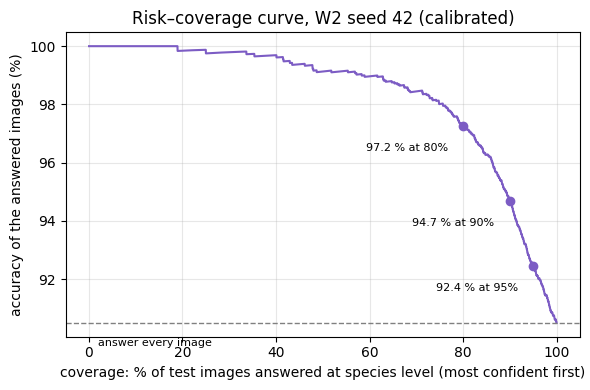

In [30]:
if not TIME_STATUS["out_of_time"]:
    # key (matched in the lower-case folder name) -> (scientific name, group, life cycle)
    SPECIES_INFO = {
        "alternanthera": ("Alternanthera philoxeroides", "broadleaf", "perennial"),
        "centella": ("Centella asiatica", "broadleaf", "perennial"),
        "ochraceus": ("Cyperus ochraceus", "sedge", "annual/perennial"),
        "fimbristylis": ("Fimbristylis littoralis", "sedge", "annual"),
        "ipomoea aquatic": ("Ipomoea aquatica", "broadleaf", "perennial"),
        "marsilea": ("Marsilea minuta", "fern", "perennial"),
        "panicum": ("Panicum repens", "grass", "perennial"),
        "paspalum": ("Paspalum scrobiculatum", "grass", "annual/perennial"),
        "pteris": ("Pteris vittata", "fern", "perennial"),
        "synedrella": ("Synedrella nodiflora", "broadleaf", "annual"),
        "commelina": ("Commelina benghalensis", "broadleaf", "annual/perennial"),
        "rotundus": ("Cyperus rotundus", "sedge", "perennial"),
        "parthenium": ("Parthenium hysterophorus", "broadleaf", "annual"),
        "hypericifolia": ("Euphorbia hypericifolia", "broadleaf", "annual"),
        "senna": ("Senna obtusifolia", "broadleaf", "annual"),
        "cynodon": ("Cynodon dactylon", "grass", "perennial"),
        "chamaecrista": ("Chamaecrista pumila", "broadleaf", "annual/perennial"),
        "boerhaavia": ("Boerhavia diffusa", "broadleaf", "perennial"),
        "chenopodium": ("Chenopodium sp.", "broadleaf", "annual"),
        "malva": ("Malva parviflora", "broadleaf", "annual"),
        "geneculata": ("Euphorbia geniculata", "broadleaf", "annual"),
        "obscura": ("Ipomoea obscura", "broadleaf", "perennial"),
        "clitoria": ("Clitoria ternatea", "broadleaf", "perennial"),
        "argemone": ("Argemone mexicana", "broadleaf", "annual"),
        "hirta": ("Euphorbia hirta", "broadleaf", "annual"),
        "digitaria": ("Digitaria sanguinalis", "grass", "annual"),
    }
    CLASS_INFO = []
    for c in class_names:
        hits = [k for k in SPECIES_INFO if k in c.lower()]
        assert len(hits) == 1, (c, hits)
        CLASS_INFO.append(SPECIES_INFO[hits[0]])
    GROUPS = sorted({g for _, g, _ in CLASS_INFO})
    GROUP_OF = np.array([GROUPS.index(g) for _, g, _ in CLASS_INFO])
    print(pd.Series([g for _, g, _ in CLASS_INFO]).value_counts().to_string())


    def group_probs(p):
        return np.stack([p[:, GROUP_OF == g].sum(1) for g in range(len(GROUPS))], 1)


    def decide(p, tau_s, tau_g):
        # returns level (0 species, 1 group, 2 not sure), species, group
        top, conf = p.argmax(1), p.max(1)
        g = GROUP_OF[top]
        gp = group_probs(p)[np.arange(len(p)), g]
        level = np.where(conf >= tau_s, 0, np.where(gp >= tau_g, 1, 2))
        return level, top, g


    def pick_threshold(scores, correct, target):
        # lowest threshold such that answers with score >= threshold are at least `target` accurate
        order = np.argsort(-scores)
        acc = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
        ok = np.where(acc >= target)[0]
        return scores[order][ok.max()] if len(ok) else 1.01


    adv_rows, ADVISORY = [], {}
    for mid, c in CAL.items():
        (lv, yv), (lt, yt), T = c["val"], c["test"], c["T"]
        pv, pt = softmax_T(lv, T), softmax_T(lt, T)
        tau_s = pick_threshold(pv.max(1), pv.argmax(1) == yv, TARGET_ACC)
        rest = pv.max(1) < tau_s
        gv = GROUP_OF[pv.argmax(1)]
        gpv = group_probs(pv)[np.arange(len(pv)), gv]
        tau_g = pick_threshold(gpv[rest], (gv == GROUP_OF[yv])[rest], TARGET_ACC) if rest.any() else 1.01
        ADVISORY[mid] = dict(T=T, tau_species=tau_s, tau_group=tau_g)
        level, top, g = decide(pt, tau_s, tau_g)
        sp, gr, ns = level == 0, level == 1, level == 2
        adv_rows.append(dict(model=mid, T=T, tau_species=tau_s, tau_group=tau_g,
                             species_answers_pct=sp.mean() * 100, species_accuracy=(top[sp] == yt[sp]).mean() * 100,
                             group_answers_pct=gr.mean() * 100, group_accuracy=(g[gr] == GROUP_OF[yt[gr]]).mean() * 100,
                             not_sure_pct=ns.mean() * 100,
                             accuracy_if_forced_on_not_sure=(top[ns] == yt[ns]).mean() * 100 if ns.any() else np.nan,
                             plain_accuracy=(top == yt).mean() * 100,
                             advice_correct_pct=((sp & (top == yt)) | (gr & (g == GROUP_OF[yt]))).mean() * 100,
                             wrong_advice_pct=((sp & (top != yt)) | (gr & (g != GROUP_OF[yt]))).mean() * 100))
    adv_df = pd.DataFrame(adv_rows)
    adv_df.to_csv(os.path.join(OUT_DIR, "advisory_levels.csv"), index=False)
    print(f"\nADVISORY LAYER ON THE TEST SET (thresholds from validation, target accuracy {TARGET_ACC:.0%})\n")
    print(adv_df.round(2).to_string(index=False))
    print("\nwrong_advice_pct = test images that received a species or group answer that was wrong "
          "(compare with 100 − plain_accuracy for the model without the layer)")

    # risk–coverage curve (species level, W2 seed 42)
    lt, yt = CAL["W2"]["test"]
    pt = softmax_T(lt, CAL["W2"]["T"])
    order = np.argsort(-pt.max(1))
    ok = (pt.argmax(1) == yt)[order]
    cov = np.arange(1, len(ok) + 1) / len(ok)
    acc = np.cumsum(ok) / np.arange(1, len(ok) + 1)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(cov * 100, acc * 100, color="#7c5cc4")
    for c_ in (0.8, 0.9, 0.95):
        k = int(c_ * len(ok)) - 1
        ax.plot(cov[k] * 100, acc[k] * 100, "o", color="#7c5cc4")
        ax.annotate(f"{acc[k] * 100:.1f} % at {c_:.0%}", (cov[k] * 100, acc[k] * 100), xytext=(-70, -18),
                    textcoords="offset points", fontsize=8)
    ax.axhline(acc[-1] * 100, ls="--", color="grey", lw=1); ax.text(2, acc[-1] * 100 - 0.8, "answer every image", fontsize=8)
    ax.set_xlabel("coverage: % of test images answered at species level (most confident first)")
    ax.set_ylabel("accuracy of the answered images (%)"); ax.grid(alpha=0.3)
    ax.set_title("Risk–coverage curve, W2 seed 42 (calibrated)")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "risk_coverage.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

## 25. Management Advice

The last step turns the decision into advice. Each answer gets:
- **what was recognised** (species or group) and how sure the model is;
- **general control methods** (cultural, mechanical) for that group and life cycle;
- **herbicide options** — *active ingredients* that rice weed-management guidance commonly lists for that weed group,
  separately for *in the rice crop* and *before planting / non-crop land*. No doses: these depend on the product,
  crop stage and local registration;
- **species notes** where a species needs special care (e.g. perennial tubers or rhizomes, health risk).

⚠️ **Must be verified.** This table is a starting point compiled from general guidance (e.g. IRRI Rice Knowledge
Bank, BRRI weed-management recommendations), not an agronomic recommendation. Before it is used in the thesis or
shown to farmers, an agronomist or the local DAE / BRRI extension service must check every entry, and the product
label must always be followed. Several Dataset 2 species are mainly upland or non-crop weeds, where rice herbicides
may not apply.

                    species     group       life_cycle
           Cyperus rotundus     sedge        perennial
   Parthenium hysterophorus broadleaf           annual
    Euphorbia hypericifolia broadleaf           annual
          Senna obtusifolia broadleaf           annual
           Cynodon dactylon     grass        perennial
        Chamaecrista pumila broadleaf annual/perennial
          Boerhavia diffusa broadleaf        perennial
            Chenopodium sp. broadleaf           annual
           Malva parviflora broadleaf           annual
       Euphorbia geniculata broadleaf           annual
            Ipomoea obscura broadleaf        perennial
          Clitoria ternatea broadleaf        perennial
          Argemone mexicana broadleaf           annual
            Euphorbia hirta broadleaf           annual
      Digitaria sanguinalis     grass           annual
     Commelina benghalensis broadleaf annual/perennial
Alternanthera philoxeroides broadleaf        perennial
          

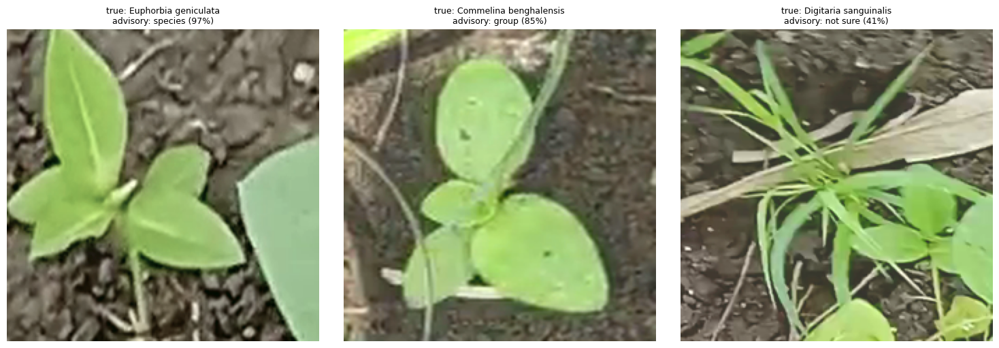

In [31]:
if not TIME_STATUS["out_of_time"]:
    DISCLAIMER = ("Indicative only — verify with an agronomist / local DAE or BRRI extension officer and follow the "
                  "product label for dose, timing and safety.")

    GROUP_ADVICE = {
        "grass": dict(
            methods="Good land preparation and levelling; keep the field flooded (3–5 cm) after transplanting; hand weeding "
                    "or rotary/cono weeder at about 15–20 and 35–40 days after transplanting; remove before seed set.",
            herbicide_in_crop="pre-emergence: pretilachlor, butachlor, oxadiazon; post-emergence: cyhalofop-butyl, "
                              "fenoxaprop-p-ethyl (with safener), bispyribac-sodium",
            herbicide_non_crop="glyphosate (non-selective) on fallow land or bunds before land preparation — never on the "
                               "standing crop"),
        "sedge": dict(
            methods="Flooding suppresses most annual sedges; hand weeding early (before 4–5 leaves); for perennial "
                    "sedges, repeated tillage in the dry season to expose and dry the tubers.",
            herbicide_in_crop="pre-emergence: pretilachlor, butachlor; post-emergence: bensulfuron-methyl, "
                              "pyrazosulfuron-ethyl, ethoxysulfuron, 2,4-D (amine), bispyribac-sodium",
            herbicide_non_crop="halosulfuron-methyl or glyphosate on fallow land (repeated applications for tubers)"),
        "broadleaf": dict(
            methods="Hand weeding or weeder before flowering; keep flooding; remove plants with roots; do not let them "
                    "set seed; clean bunds and irrigation channels.",
            herbicide_in_crop="2,4-D (amine), MCPA, metsulfuron-methyl + chlorimuron-ethyl, bensulfuron-methyl, "
                              "carfentrazone-ethyl",
            herbicide_non_crop="glyphosate or 2,4-D on fallow land, bunds and channels"),
        "fern": dict(
            methods="Hand weeding; drain and dry the field between crops; good levelling (ferns favour standing water "
                    "in low spots).",
            herbicide_in_crop="2,4-D (amine), bensulfuron-methyl, metsulfuron-methyl (reported effective on Marsilea)",
            herbicide_non_crop="glyphosate on fallow land"),
    }
    SPECIES_NOTES = {
        "Cyperus rotundus": "Perennial with underground tubers: hand weeding alone regrows; combine tillage and herbicide.",
        "Cynodon dactylon": "Perennial with rhizomes and stolons: pieces regrow; dig out rhizomes, control on bunds.",
        "Panicum repens": "Perennial with deep rhizomes: control before land preparation; avoid spreading rhizome pieces.",
        "Alternanthera philoxeroides": "Fragments regrow and float to new areas: do not chop into the water; remove "
                                       "whole plants, repeated control needed.",
        "Parthenium hysterophorus": "Health risk (skin allergy, asthma): wear gloves and cover skin; uproot before "
                                    "flowering.",
        "Commelina benghalensis": "Stems root at the nodes and tolerate many herbicides: remove whole plants and do not "
                                  "leave cut stems in moist soil.",
        "Argemone mexicana": "Spiny and poisonous seeds: wear gloves; do not let it set seed near grain.",
        "Ipomoea aquatica": "Also grown as a vegetable: confirm with the farmer before treating it as a weed.",
        "Centella asiatica": "Also a medicinal plant: confirm with the farmer before treating it as a weed.",
    }
    NOT_SURE_ADVICE = ("Not sure. Take a new photo closer to one plant, in daylight, with the leaves in focus — or show "
                       "the plant to an extension officer before any herbicide is used.")


    def advise(prob_row, tau_s, tau_g):
        level, top, g = decide(prob_row[None], tau_s, tau_g)
        level, top, g = int(level[0]), int(top[0]), int(g[0])
        name, group, cycle = CLASS_INFO[top]
        out = dict(level=["species", "group", "not sure"][level], confidence=float(prob_row.max()))
        if level == 2:
            out["message"] = NOT_SURE_ADVICE
            return out
        if level == 0:
            out["recognised"] = f"{name} ({group}, {cycle})"
        else:
            members = [CLASS_INFO[k][0] for k in np.argsort(-prob_row) if GROUP_OF[k] == g][:2]
            out["recognised"] = f"a {GROUPS[g]} weed (most likely {' or '.join(members)})"
            out["group_confidence"] = float(prob_row[GROUP_OF == g].sum())
        adv = GROUP_ADVICE[GROUPS[g]]
        out.update(methods=adv["methods"], herbicide_in_crop=adv["herbicide_in_crop"],
                   herbicide_non_crop=adv["herbicide_non_crop"], disclaimer=DISCLAIMER)
        if level == 0 and name in SPECIES_NOTES:
            out["species_note"] = SPECIES_NOTES[name]
        return out


    # the full advice table (one row per class) and the rules, for the thesis appendix / an app
    table_rows = []
    for c, (name, group, cycle) in zip(class_names, CLASS_INFO):
        adv = GROUP_ADVICE[group]
        table_rows.append(dict(folder=c, species=name, group=group, life_cycle=cycle, methods=adv["methods"],
                               herbicide_in_crop=adv["herbicide_in_crop"], herbicide_non_crop=adv["herbicide_non_crop"],
                               species_note=SPECIES_NOTES.get(name, "")))
    pd.DataFrame(table_rows).to_csv(os.path.join(OUT_DIR, "advice_table.csv"), index=False)
    with open(os.path.join(OUT_DIR, "advisory_rules.json"), "w") as f:
        json.dump(dict(model="W2 (seed 42)", **{k: float(v) for k, v in ADVISORY["W2"].items()}, groups=GROUPS,
                       target_accuracy=TARGET_ACC, disclaimer=DISCLAIMER), f, indent=1)
    print(pd.DataFrame(table_rows)[["species", "group", "life_cycle"]].to_string(index=False))

    # ---- examples: one test image per level ----
    lt, yt = CAL["W2"]["test"]
    pt = softmax_T(lt, CAL["W2"]["T"])
    a = ADVISORY["W2"]
    level, _, _ = decide(pt, a["tau_species"], a["tau_group"])
    rs = np.random.RandomState(4)
    examples = [int(rs.choice(np.where(level == L)[0])) for L in (0, 1, 2) if (level == L).any()]
    fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 5))
    for ax, i in zip(np.atleast_1d(axes), examples):
        out = advise(pt[i], a["tau_species"], a["tau_group"])
        ax.imshow(harmonize(test_subset[i][0]).resize((IMG_SIZE, IMG_SIZE))); ax.axis("off")
        ax.set_title(f"true: {CLASS_INFO[yt[i]][0]}\nadvisory: {out['level']} ({out['confidence']:.0%})", fontsize=9)
        print(f"\n--- test image {i}: true class {CLASS_INFO[yt[i]][0]} ---")
        for k, v in out.items():
            print(f"  {k}: {v}")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "advisory_examples.png"), dpi=150); plt.show()
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

---
# Part 5 — Speed and Summary

## 26. CPU Latency (Same Machine for Every Model)

Every model is timed again in this session on the same CPU: batch of 1, 224×224, 5 warm-up runs, then the median of
50 runs. Report "CPU latency on Kaggle", not
"on-device latency".

In [32]:
if not TIME_STATUS["out_of_time"]:
    torch.set_num_threads(os.cpu_count() or 1)
    x_cpu = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    cpu_rows = []
    for f in CMP:   # latency does not depend on the weights, so the freshly built model is timed
        m = FAMILIES[f][2]().cpu().eval()
        with torch.no_grad():
            for _ in range(5):
                m(x_cpu)
            times = []
            for _ in range(50):
                t0 = time.perf_counter()
                m(x_cpu)
                times.append((time.perf_counter() - t0) * 1000)
        cpu_rows.append(dict(id=f, model=FAMILIES[f][0], params_M=count_params(m)[0] / 1e6,
                             cpu_ms_median=float(np.median(times)), cpu_ms_p90=float(np.percentile(times, 90))))
        del m
    cpu_df = pd.DataFrame(cpu_rows).set_index("id")
    cpu_df.to_csv(os.path.join(OUT_DIR, "cpu_latency.csv"))
    print(f"CPU latency, batch of 1, {os.cpu_count()} threads\n")
    print(cpu_df.round(3).to_string())
else:
    print("Skipped: training is not finished yet (time budget) — see the last cell")

CPU latency, batch of 1, 4 threads

                                model  params_M  cpu_ms_median  cpu_ms_p90
id                                                                        
W2   WeedNet-v4 + QKV head (proposed)     0.542         11.921      12.839
W1  WeedNet-v4, plain head (ablation)     0.513         11.108      12.802
B1             MobileNetV3-Small 0.5x     0.595         10.097      10.603
S1                  ShuffleNetV2 0.5x     0.368         13.940      15.250
L1                      PP-LCNet 0.5x     0.633          9.388      10.487
Q1                     SqueezeNet 1.1     0.736         14.879      16.444
M1             MobileNetV3-Small 1.0x     1.545         12.044      12.640


## 27. Final Summary and Run Status

All key numbers in one place. `INCOMPLETE` means the time budget ran out and everything so far is saved: attach
**this version's output** (keep the other inputs attached) and run **Save & Run All** again.

In [33]:
print("=" * 100)
if not TIME_STATUS["out_of_time"]:
    w2 = EXPERIMENTS[PROPOSED]
    print(f"PROPOSED MODEL: {PROPOSED} — {FAMILIES[PROPOSED][0]}: {w2['total_params']:,} params, "
          f"{w2['gmacs']:.3f} GMACs, {w2['size_mb']:.2f} MB\n")
    print("1. TEST MACRO-F1, mean ± std over seeds")
    for fam in SEED_FAMS:
        r = seed_summary.loc[fam]
        print(f"   {fam} {FAMILIES[fam][0]:<34} {r[('macro_f1', 'mean')]:.2f} ± {r[('macro_f1', 'std')]:.2f} %"
              f"  (n = {SEED_COUNTS[fam]})")
    for b_, v in PAIRED.items():
        n = len(v["diffs"])
        sig = sum(p < 0.05 for p in v["ps"])
        word = ("consistent and significant" if sig == n and v["wins"] in (0, n) else "no consistent significant difference")
        print(f"   {PROPOSED} − {b_}: {np.mean(v['diffs']):+.2f} pp; better in {v['wins']}/{n} seeds; significant in "
              f"{sig}/{n} -> {word}")
    print("\n2. SAME-SIZE COMPARISON (seed 42, McNemar, Holm-adjusted)")
    for _, r in vs_df.iterrows():
        word = (f"{PROPOSED} better" if r.delta_f1 > 0 else f"{PROPOSED} worse") if r.significant else "no significant difference"
        print(f"   vs {r.other} {r.other_model:<34} ({r.size_vs_W2:.2f}x size): {r.delta_f1:+.2f} pp, "
              f"p = {r.p_holm:.4f} -> {word}")
    print(f"\n3. OVERFITTING (seed 42): train−val gap " + ", ".join(f"{i} {g:.1f}" for i, g in of_df["gap"].items()) + " pp")
    if "src_df" in globals():
        print("\n4. SOURCE TEST (macro-F1 on each dataset's test images)")
        for lab, g in src_df.groupby("source", sort=False):
            v = dict(zip(g["scoring"], g["macro_f1"]))
            print(f"   {lab}: 26-class {v['26-class W1']:.2f} | source given {v['26-class W1, source given']:.2f} | "
                  f"single-source {v['single-source W1']:.2f}")
    print(f"\n5. ATTENTION: top-5 of 49 positions get {conc['top5_share_%'][0]:.1f} % of the attention (uniform 10.2 %)")
    print(f"   faithfulness: deletion AUC {faith_df.deletion_auc[0]:.3f} vs random {faith_df.deletion_auc[1]:.3f}; "
          f"insertion {faith_df.insertion_auc[0]:.3f} vs {faith_df.insertion_auc[1]:.3f}; beats random on "
          f"{faith_df.beats_random_deletion_pct[0]:.0f} % / {faith_df.beats_random_insertion_pct[0]:.0f} % of images")
    print("   sanity check: " + ", ".join(f"{r.randomised} {r.attention_spearman:.3f}" for _, r in sanity_df.iterrows()))
    print("\n6. CALIBRATION + ADVISORY LAYER")
    for (_, c), (_, a) in zip(cal_df.iterrows(), adv_df.iterrows()):
        print(f"   {c.model}: T = {c.temperature:.2f}, ECE {c.test_ece_before:.2f} -> {c.test_ece_after:.2f} % | species "
              f"{a.species_answers_pct:.1f} % ({a.species_accuracy:.1f} % correct), group {a.group_answers_pct:.1f} %, "
              f"not sure {a.not_sure_pct:.1f} % | wrong advice {a.wrong_advice_pct:.2f} % vs {100 - a.plain_accuracy:.2f} %")
    print("\n7. CPU latency (ms/img): " + ", ".join(f"{i} {v:.1f}" for i, v in cpu_df["cpu_ms_median"].items()))
    print("-" * 100)

used_h = (time.time() - SESSION_START) / 3600
if TIME_STATUS["out_of_time"]:
    print(f"INCOMPLETE after {used_h:.1f} h — time budget ({TIME_BUDGET_HOURS:g} h) reached; everything so far is "
          f"saved in {OUT_DIR}/")
    print("NEXT: Add Input -> Your Work -> Notebooks -> THIS notebook (this version), then Save Version -> Save & Run All.")
else:
    print(f"COMPLETE after {used_h:.1f} h.")
print("=" * 100)

PROPOSED MODEL: W2 — WeedNet-v4 + QKV head (proposed): 541,506 params, 0.049 GMACs, 2.19 MB

1. TEST MACRO-F1, mean ± std over seeds
   W2 WeedNet-v4 + QKV head (proposed)   91.29 ± 0.36 %  (n = 3)
   W1 WeedNet-v4, plain head (ablation)  91.22 ± 1.05 %  (n = 3)
   B1 MobileNetV3-Small 0.5x             88.25 ± 0.64 %  (n = 3)
   M1 MobileNetV3-Small 1.0x             92.94 ± 0.30 %  (n = 3)
   W2 − W1: +0.07 pp; better in 1/3 seeds; significant in 0/3 -> no consistent significant difference
   W2 − B1: +3.04 pp; better in 3/3 seeds; significant in 3/3 -> consistent and significant
   W2 − M1: -1.65 pp; better in 0/3 seeds; significant in 3/3 -> consistent and significant

2. SAME-SIZE COMPARISON (seed 42, McNemar, Holm-adjusted)
   vs W1 WeedNet-v4, plain head (ablation)  (0.95x size): -0.84 pp, p = 0.3997 -> no significant difference
   vs B1 MobileNetV3-Small 0.5x             (1.10x size): +2.99 pp, p = 0.0000 -> W2 better
   vs S1 ShuffleNetV2 0.5x                  (0.68x size): +1.4